# Exploratory data analysis: MOT17 (Phase 1, data cleaning and processing)

This notebook carries out proposal section 4.0: it examines the MOT17 ground truth, looks for missing frames,
keeps only the boxes the model learns from, and writes a model-ready dataset to `outputs/data/`.

* The raw data under `train/` and `test/` is **only read, never changed**.
* The ground truth is never altered: rows are only *selected*, and boxes only change *units* (pixels → fractions of the frame).
* Run it with **Restart kernel → Run all**. It takes roughly 5–10 minutes (hashing every frame and computing pixel statistics are the slow parts).

**All data preparation happens in this notebook.** Every other notebook (the DeepSORT baseline, the model) only *reads* what this one writes, so they all run on exactly the same input:
1. **Prepared files** in `outputs/data/`: `frames.csv`, `boxes.csv`, `videos.csv`, `detections.csv`, `pixel_stats.json` and the split files in `splits/`.
2. **`mot17_data.py`** (written by section 0, next to this notebook): the shared code that opens frames, resizes and normalizes them, converts boxes, and builds the PyTorch datasets.
3. **`manifest.json`**: an MD5 fingerprint of every prepared file. Other notebooks call `mot17_data.data_version()`, which stops with an error if a file is missing or changed, and gives a short ID to record next to their results.

Run order: this notebook first, then any other notebook.

In [1]:
# ---- Imports ----
import configparser                  # reads each video's seqinfo.ini
import hashlib                       # MD5 hashes, to prove the three copies of a video are identical
import json                          # saves the pixel statistics
import random                        # picks random boxes / frames for spot checks
import time                          # times the slow steps
from pathlib import Path             # file paths that work on Windows, Mac, Linux and Colab

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch                         # (frame loading and the datasets are in mot17_data.py, section 0)

# ---- Paths: the only place in the notebook where paths are defined ----
# Jupyter and VS Code start a notebook inside its own folder, which is MOT17/MOT17/.
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parents[1]            # two folders up from the notebook
DATA_ROOT = PROJECT_ROOT / "MOT17" / "MOT17"      # holds train/ and test/ (read-only)
OUTPUT_ROOT = PROJECT_ROOT / "outputs"            # everything this notebook writes goes here
OUTPUT_DATA = OUTPUT_ROOT / "data"
OUTPUT_FIGURES = OUTPUT_ROOT / "figures"
OUTPUT_DATA.mkdir(parents=True, exist_ok=True)
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)

# Stop straight away with a clear message if the data isn't where we expect it.
assert (DATA_ROOT / "train").is_dir(), f"MOT17 train/ folder not found in {DATA_ROOT}. Is the notebook running from its own folder?"

# ---- Settings used throughout the notebook ----
DETECTOR_COPY = "FRCNN"                      # DECISION 1.1: use only the -FRCNN copy of each video
TARGET_WIDTH, TARGET_HEIGHT = 1920, 1088     # 1.6: every frame is resized to this size as it's loaded
VISIBILITY_THRESHOLD = None                  # OPTION 1.4: e.g. 0.1 drops boxes under 10% visible; None keeps all

# DECISION 1.7: split by whole video (explained in section 1.7). Needed early because
# the pixel statistics in 1.6 must come from the training split only.
# Changed 2026-11-15 (Rowan): validation is MOT17-10, not MOT17-11. MOT17-11's people are much bigger
# than the test video's (median 359 px vs 84 px tall), so it was a poor stand-in for the test video.
SPLIT_OF_VIDEO = {
    "MOT17-02": "train", "MOT17-04": "train", "MOT17-05": "train", "MOT17-09": "train", "MOT17-11": "train",
    "MOT17-10": "val",
    "MOT17-13": "test",
}
SPLITS = ["train", "val", "test"]

# The 9 columns of gt.txt, in order.
GT_COLUMNS = ["frame", "id", "left", "top", "width", "height", "use", "class", "visibility"]

# Fixed random seed so the spot checks pick the same boxes and frames every run.
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Collected as the notebook runs, and saved in section 1.9.
problems = []   # every missing frame, unreadable frame, invalid row, duplicate and ID gap -> problems.csv
report = {}     # section heading -> Markdown text                                          -> data_report.md

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_ROOT:   ", DATA_ROOT)
print("OUTPUT_ROOT: ", OUTPUT_ROOT)

# ---- Device: the GPU is the default for every model in this project; the CPU is only a fallback ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False       # don't let cuDNN choose algorithms by timing them (choices can differ run to run)
torch.backends.cudnn.deterministic = True    # use deterministic cuDNN algorithms where they exist
print("torch", torch.__version__, "| DEVICE:", DEVICE,
      f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")
if DEVICE.type == "cpu":
    print("WARNING: CUDA is not available, so models will run on the CPU (much slower). "
          "Install the CUDA build of PyTorch (see requirements.txt).")

PROJECT_ROOT: C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project
DATA_ROOT:    C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\MOT17\MOT17
OUTPUT_ROOT:  C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs
torch 2.14.0+cu130 | DEVICE: cuda (NVIDIA GeForce RTX 5070)


In [2]:
# ---- Small helper functions used by several sections ----

def read_seqinfo(folder):
    """Read a video folder's seqinfo.ini and return its length, frame size and frame rate as numbers."""
    parser = configparser.ConfigParser()
    parser.read(folder / "seqinfo.ini")
    s = parser["Sequence"]
    return {
        "seq_length": int(s["seqLength"]),
        "im_width": int(s["imWidth"]),
        "im_height": int(s["imHeight"]),
        "frame_rate": int(s["frameRate"]),
    }


def add_problem(problem, video, frame=None, id=None, detail=""):
    """Record one problem found in the data (it ends up in problems.csv)."""
    problems.append({"problem": problem, "video": video, "frame": frame, "id": id, "detail": detail})


def fmt(value, decimals):
    """Format one table value for the Markdown report."""
    if isinstance(value, (bool, np.bool_)):
        return "yes" if value else "**NO**"
    if isinstance(value, (int, np.integer)):
        return f"{value:,}"
    if isinstance(value, (float, np.floating)):
        return "" if pd.isna(value) else f"{value:,.{decimals}f}"
    return str(value)


def md_table(df, decimals=1):
    """Turn a DataFrame into a Markdown table (numbers rounded to `decimals` places)."""
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"
    divider = "|" + "|".join(["---"] * len(df.columns)) + "|"
    rows = ["| " + " | ".join(fmt(v, decimals) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([header, divider] + rows)


# ---- Expected numbers from the build plan (checked 2026-11-14), compared against what we find ----
EXPECTED = pd.DataFrame(
    [
        # video,     frames, width, height, fps, pedestrian rows, pedestrian IDs, extend past edge, centre outside
        ("MOT17-02",    600,  1920,  1080,  30,  18581,  62,    317,   30),
        ("MOT17-04",   1050,  1920,  1080,  30,  47557,  83,  12319, 4183),
        ("MOT17-05",    837,   640,   480,  14,   6917, 133,   1546,  164),
        ("MOT17-09",    525,  1920,  1080,  30,   5325,  26,    592,  126),
        ("MOT17-10",    654,  1920,  1080,  30,  12839,  57,    499,  146),
        ("MOT17-11",    900,  1920,  1080,  30,   9436,  75,    684,  103),
        ("MOT17-13",    750,  1920,  1080,  25,  11642, 110,    411,   83),
    ],
    columns=["video", "frames", "width", "height", "fps", "ped_rows", "ped_ids", "extend_past_edge", "centre_outside"],
).set_index("video")
EXPECTED_TEST_FRAMES = 5919                                   # official test/ videos, all 7 together
EXPECTED_SPLIT_FRAMES = {"train": 3912, "val": 654, "test": 750}   # for the 2026-11-15 split (val = MOT17-10)

## 0. Shared data code (`mot17_data.py`)
The next cell writes `mot17_data.py` next to this notebook. It's the **only** definition of how a frame is opened, resized and normalized, how boxes convert back to pixels, and how the PyTorch datasets work. This notebook uses it, and so do the DeepSORT and model notebooks (`import mot17_data`), so every notebook sees exactly the same input.

To change how data is loaded, edit this cell and re-run the notebook, not the `.py` file (it's overwritten on every run).

In [3]:
%%writefile mot17_data.py
"""
mot17_data.py: the ONE definition of how every notebook loads the prepared MOT17 data.

WRITTEN BY "Exploratory data analysis.ipynb" (section 0). Don't edit this file by hand: edit that
cell and re-run the notebook, so all data preparation stays in one place.

Use it from any notebook in MOT17/MOT17/:
    import mot17_data
    print(mot17_data.data_version())                  # stops if the prepared data is missing or changed
    train_set = mot17_data.MOT17Frames("train")       # one item per frame (model input + ground truth)
    train_loader = mot17_data.make_loader(train_set, "train")
"""
import hashlib
import json
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF

# ---- Paths, worked out from where this file is, so they're the same in every notebook ----
DATA_ROOT = Path(__file__).resolve().parent      # MOT17/MOT17/: holds train/ and test/ (read-only)
PROJECT_ROOT = DATA_ROOT.parents[1]
OUTPUT_DATA = PROJECT_ROOT / "outputs" / "data"  # the prepared files written by the EDA notebook
MANIFEST = OUTPUT_DATA / "manifest.json"         # MD5 of every prepared file (written last by the EDA notebook)

# ---- Settings every notebook shares ----
DETECTOR_COPY = "FRCNN"                          # the copy of each video used throughout the project
TARGET_WIDTH, TARGET_HEIGHT = 1920, 1088         # the model's input size (every frame is resized to this)
SPLITS = ["train", "val", "test"]


# ---------------------------------------------------------------- prepared files
def file_md5(path):
    """MD5 hash of a file's bytes: an unchanged file keeps the same hash."""
    return hashlib.md5(Path(path).read_bytes()).hexdigest()


def data_version():
    """Check every prepared file, and this file, are exactly what the EDA notebook wrote, and return a short ID for
    this version of the data (record it next to any results). Raises an error if a file is missing or changed."""
    if not MANIFEST.exists():
        raise FileNotFoundError(f"{MANIFEST} not found. Run 'Exploratory data analysis.ipynb' first (Restart -> Run all).")
    manifest = json.loads(MANIFEST.read_text())
    if file_md5(__file__) != manifest["code_md5"]:
        raise RuntimeError("mot17_data.py differs from the version the EDA notebook wrote. Make changes in the "
                           "notebook's section 0 and re-run 'Exploratory data analysis.ipynb'.")
    for name, md5 in manifest["files"].items():
        path = OUTPUT_DATA / name
        if not path.exists():
            raise FileNotFoundError(f"{path} is missing. Re-run 'Exploratory data analysis.ipynb'.")
        if file_md5(path) != md5:
            raise RuntimeError(f"{path} changed after the EDA notebook wrote it. Re-run 'Exploratory data analysis.ipynb'.")
    return manifest["version"]


def read_prepared(name):
    """Read one prepared file from outputs/data/: "frames", "boxes", "videos", "detections" (tables) or
    "pixel_stats" (a dictionary). Split files are named like "splits/train_boxes"."""
    path = OUTPUT_DATA / (f"{name}.json" if name == "pixel_stats" else f"{name}.csv")
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run 'Exploratory data analysis.ipynb' first.")
    return json.loads(path.read_text()) if path.suffix == ".json" else pd.read_csv(path)


# ---------------------------------------------------------------- frames
def open_original(image_path):
    """Open one frame (path relative to DATA_ROOT, as in frames.csv) as an RGB image at its ORIGINAL size.
    Used by DeepSORT, which works in original pixels."""
    with Image.open(DATA_ROOT / image_path) as img:
        return img.convert("RGB")


def open_resized(image_path):
    """Open one frame as an RGB image resized to 1920 x 1088 (the model's input size). Nothing is cropped or padded."""
    return open_original(image_path).resize((TARGET_WIDTH, TARGET_HEIGHT), Image.BILINEAR)


def load_frame(image_path, mean=None, std=None):
    """Turn one frame into the model's input: a float tensor [3, 1088, 1920].
    1. resize to 1920 x 1088
    2. scale pixels from 0-255 to 0-1 (what transforms.ToTensor() does)
    3. if mean and std are given, normalize each colour channel: (pixel - mean) / std
    """
    image = TF.to_tensor(open_resized(image_path))     # [3, 1088, 1920], values 0-1
    if mean is not None:
        image = TF.normalize(image, mean, std)
    return image


# ---------------------------------------------------------------- boxes
def boxes_to_pixels(boxes, image_width, image_height):
    """Boxes stored as (cx, cy, w, h) fractions of the ORIGINAL frame -> (left, top, width, height) in original pixels.
    `boxes` is a table with columns cx, cy, w, h; the sizes are numbers or columns of the same length.
    Rounded to 6 decimals: converting to fractions and back leaves noise of about 1e-13 px (e.g. 1288.9999999999995
    instead of 1289), and code that cuts boxes out with whole pixels (DeepSORT's appearance crops) would then be
    one pixel off. gt.txt values are whole numbers, so rounding gives back exactly the gt.txt values."""
    width = boxes["w"] * image_width
    height = boxes["h"] * image_height
    pixels = pd.DataFrame({"left": boxes["cx"] * image_width - width / 2,
                           "top": boxes["cy"] * image_height - height / 2,
                           "width": width, "height": height}, index=boxes.index)
    return pixels.round(6)


# ---------------------------------------------------------------- PyTorch datasets
class MOT17Frames(Dataset):
    """One item per frame of a split ("train", "val" or "test").

    Each item is a dictionary:
      image       float tensor [3, 1088, 1920]: resized, scaled to 0-1, normalized with pixel_stats.json
      orig_size   tensor [2] = (original width, original height), to turn outputs back into original pixels
      boxes       float tensor [N, 4] = (cx, cy, w, h) as 0-1 fractions of the original frame
      ids         int tensor [N] = person IDs (only meaningful within one video)
      video, frame  which frame this is
    """

    def __init__(self, split, normalize=True):
        self.data_version = data_version()            # stops here if the prepared data is missing or changed
        frames = read_prepared("frames")
        self.frames = frames[frames["split"] == split].sort_values(["video", "frame"]).reset_index(drop=True)
        boxes = read_prepared("boxes")
        boxes = boxes[boxes["split"] == split]
        # Group the boxes by frame once, so looking up a frame's boxes is fast.
        self.targets = {
            key: (torch.tensor(g[["cx", "cy", "w", "h"]].to_numpy(), dtype=torch.float32),
                  torch.tensor(g["id"].to_numpy(), dtype=torch.int64))
            for key, g in boxes.groupby(["video", "frame"])
        }
        stats = read_prepared("pixel_stats")
        self.mean = stats["mean"] if normalize else None
        self.std = stats["std"] if normalize else None

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, index):
        row = self.frames.iloc[index]
        key = (row["video"], int(row["frame"]))
        # A frame with no pedestrians gets empty tensors.
        boxes, ids = self.targets.get(key, (torch.zeros((0, 4)), torch.zeros(0, dtype=torch.int64)))
        return {
            "image": load_frame(row["image_path"], self.mean, self.std),
            "orig_size": torch.tensor([int(row["image_width"]), int(row["image_height"])]),
            "boxes": boxes,
            "ids": ids,
            "video": row["video"],
            "frame": int(row["frame"]),
        }


class MOT17FramePairs(Dataset):
    """One item per pair of consecutive frames (t-1, t) of the same video: returns (item at t-1, item at t).
    The IDs show which box in frame t is which person in frame t-1, which is what the transformer learns from."""

    def __init__(self, split, normalize=True):
        self.frames = MOT17Frames(split, normalize)
        self.data_version = self.frames.data_version
        table = self.frames.frames
        position = {(v, f): i for i, (v, f) in enumerate(zip(table["video"], table["frame"]))}
        # Pair each frame with the frame just before it, only if that frame exists (same video, frame number - 1).
        self.pairs = [(position[(v, f - 1)], i) for i, (v, f) in enumerate(zip(table["video"], table["frame"]))
                      if (v, f - 1) in position]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        previous, current = self.pairs[index]
        return self.frames[previous], self.frames[current]


def collate_frames(items):
    """Batch frames: images stack into [B, 3, 1088, 1920]; boxes and IDs stay as lists (frames have different numbers of boxes)."""
    return {
        "images": torch.stack([item["image"] for item in items]),
        "orig_sizes": torch.stack([item["orig_size"] for item in items]),
        "boxes": [item["boxes"] for item in items],
        "ids": [item["ids"] for item in items],
        "videos": [item["video"] for item in items],
        "frames": [item["frame"] for item in items],
    }


def collate_pairs(items):
    """Batch pairs: returns (batch of t-1 frames, batch of t frames). A pair's two frames stay together and in order."""
    return collate_frames([p[0] for p in items]), collate_frames([p[1] for p in items])


def make_loader(dataset, split, batch_size=2, num_workers=0, pin_memory=None):
    """Training data is shuffled; validation and test keep their order. num_workers=0 loads frames in the
    notebook's own process (simplest); a larger number loads them in parallel worker processes.
    pin_memory (default: on when CUDA is available) puts batches in page-locked memory, which copies to the GPU faster."""
    collate = collate_pairs if isinstance(dataset, MOT17FramePairs) else collate_frames
    if pin_memory is None:
        pin_memory = torch.cuda.is_available()
    return DataLoader(dataset, batch_size=batch_size, shuffle=(split == "train"), collate_fn=collate,
                      num_workers=num_workers, pin_memory=pin_memory)


def batch_to_device(batch, device):
    """Move a batch from make_loader to `device` (e.g. the notebook's DEVICE): every tensor, including the
    per-frame lists of boxes and IDs. Works for frame batches and for (t-1, t) pair batches."""
    if isinstance(batch, tuple):
        return tuple(batch_to_device(b, device) for b in batch)
    moved = {}
    for key, value in batch.items():
        if torch.is_tensor(value):
            moved[key] = value.to(device, non_blocking=True)
        elif isinstance(value, list) and value and torch.is_tensor(value[0]):
            moved[key] = [v.to(device, non_blocking=True) for v in value]
        else:
            moved[key] = value          # video names and frame numbers stay as they are
    return moved

Overwriting mot17_data.py


In [4]:
# Load the module just written. reload() makes a re-run of this notebook pick up any edit to the cell above.
import importlib
import mot17_data
importlib.reload(mot17_data)

# The notebook and the module must agree on where the data is and on the model's input size.
assert mot17_data.DATA_ROOT == DATA_ROOT.resolve(), (mot17_data.DATA_ROOT, DATA_ROOT)
assert mot17_data.OUTPUT_DATA == OUTPUT_DATA.resolve(), (mot17_data.OUTPUT_DATA, OUTPUT_DATA)
assert (mot17_data.TARGET_WIDTH, mot17_data.TARGET_HEIGHT, mot17_data.DETECTOR_COPY, mot17_data.SPLITS) == \
       (TARGET_WIDTH, TARGET_HEIGHT, DETECTOR_COPY, SPLITS)
from mot17_data import open_original, open_resized, load_frame, boxes_to_pixels
print("Shared data code loaded from", mot17_data.__file__)

Shared data code loaded from C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\MOT17\MOT17\mot17_data.py


## 1.1 Inventory, and one copy per video
Lists every video folder, reads its `seqinfo.ini`, and proves the three detector copies (`-DPM`, `-FRCNN`, `-SDP`) of each video are identical, so only the `-FRCNN` copy is used.

In [5]:
# List every video folder in train/ and test/ and read its seqinfo.ini.
rows = []
for split_folder in ["train", "test"]:
    for folder in sorted((DATA_ROOT / split_folder).iterdir()):
        if not folder.is_dir():
            continue
        video, detector = folder.name.rsplit("-", 1)          # "MOT17-02-FRCNN" -> "MOT17-02", "FRCNN"
        rows.append({
            "folder": split_folder,
            "video": video,
            "detector": detector,
            **read_seqinfo(folder),
            "images_found": len(list((folder / "img1").glob("*.jpg"))),
            "has_gt": (folder / "gt" / "gt.txt").is_file(),
        })
inventory = pd.DataFrame(rows)

print(f"{len(inventory)} folders = {inventory['video'].nunique()} videos x {inventory['detector'].nunique()} copies "
      f"({sorted(inventory['detector'].unique())})")
print("Folders per split:", inventory.groupby("folder").size().to_dict())
display(inventory[inventory["detector"] == DETECTOR_COPY].reset_index(drop=True))

42 folders = 14 videos x 3 copies (['DPM', 'FRCNN', 'SDP'])
Folders per split: {'test': 21, 'train': 21}


,folder,video,detector,seq_length,im_width,im_height,frame_rate,images_found,has_gt
0,train,MOT17-02,FRCNN,600,1920,1080,30,600,True
1,train,MOT17-04,FRCNN,1050,1920,1080,30,1050,True
2,train,MOT17-05,FRCNN,837,640,480,14,837,True
3,train,MOT17-09,FRCNN,525,1920,1080,30,525,True
4,train,MOT17-10,FRCNN,654,1920,1080,30,654,True
5,train,MOT17-11,FRCNN,900,1920,1080,30,900,True
6,train,MOT17-13,FRCNN,750,1920,1080,25,750,True
7,test,MOT17-01,FRCNN,450,1920,1080,30,450,False
8,test,MOT17-03,FRCNN,1500,1920,1080,30,1500,False
9,test,MOT17-06,FRCNN,1194,640,480,14,1194,False


In [6]:
# Compare the three copies of every video: file names, file sizes, the MD5 hash of every frame,
# the gt.txt bytes and the seqinfo.ini numbers. This reads every frame once (about 5.7 GB), so it takes a minute or two.

def file_md5(path):
    """MD5 hash of a file's bytes: two files with the same hash have the same content."""
    return hashlib.md5(path.read_bytes()).hexdigest()


def describe_copy(folder):
    """Everything compared between copies of one video."""
    images = sorted((folder / "img1").glob("*.jpg"))
    gt_path = folder / "gt" / "gt.txt"
    return {
        "names": [p.name for p in images],
        "sizes": [p.stat().st_size for p in images],
        "md5": [file_md5(p) for p in images],
        "gt": gt_path.read_bytes() if gt_path.is_file() else None,   # test videos have no gt.txt
        "seqinfo": read_seqinfo(folder),
    }


start = time.time()
rows = []
for (split_folder, video), copies in inventory.groupby(["folder", "video"]):
    reference = describe_copy(DATA_ROOT / split_folder / f"{video}-{DETECTOR_COPY}")   # the FRCNN copy
    row = {"folder": split_folder, "video": video, "frames_hashed": len(reference["md5"])}
    for key in ["names", "sizes", "md5", "gt", "seqinfo"]:
        row[f"{key}_match"] = True
    for detector in copies["detector"]:
        if detector == DETECTOR_COPY:
            continue
        other = describe_copy(DATA_ROOT / split_folder / f"{video}-{detector}")
        for key in ["names", "sizes", "md5", "gt", "seqinfo"]:
            if other[key] != reference[key]:
                row[f"{key}_match"] = False
                add_problem("copies_differ", video, detail=f"{detector} copy differs from {DETECTOR_COPY} in {key}")
    rows.append(row)
    print(f"  {video}: compared {len(copies)} copies of {row['frames_hashed']} frames")
copy_check = pd.DataFrame(rows)
print(f"Done in {time.time() - start:.0f} s")
display(copy_check)

match_columns = [c for c in copy_check.columns if c.endswith("_match")]
all_identical = bool(copy_check[match_columns].all().all())
print("All three copies identical for every video:", all_identical)
# DECISION 1.1: if any copy differs, stop and report it rather than silently picking one.
if not all_identical:
    raise RuntimeError("STOP: some copies differ (see table above). Report this to Rowan before going on.")

  MOT17-01: compared 3 copies of 450 frames


  MOT17-03: compared 3 copies of 1500 frames


  MOT17-06: compared 3 copies of 1194 frames


  MOT17-07: compared 3 copies of 500 frames


  MOT17-08: compared 3 copies of 625 frames


  MOT17-12: compared 3 copies of 900 frames


... (6 outputs left out)

  MOT17-11: compared 3 copies of 900 frames


  MOT17-13: compared 3 copies of 750 frames
Done in 20 s


,folder,video,frames_hashed,names_match,sizes_match,md5_match,gt_match,seqinfo_match
0,test,MOT17-01,450,True,True,True,True,True
1,test,MOT17-03,1500,True,True,True,True,True
2,test,MOT17-06,1194,True,True,True,True,True
3,test,MOT17-07,500,True,True,True,True,True
4,test,MOT17-08,625,True,True,True,True,True
5,test,MOT17-12,900,True,True,True,True,True
6,test,MOT17-14,750,True,True,True,True,True
7,train,MOT17-02,600,True,True,True,True,True
8,train,MOT17-04,1050,True,True,True,True,True
9,train,MOT17-05,837,True,True,True,True,True


All three copies identical for every video: True


In [7]:
# Keep one copy (FRCNN) of each video. `videos` is the list of the 14 videos used from here on.
videos = inventory[inventory["detector"] == DETECTOR_COPY].copy().reset_index(drop=True)
videos["path"] = [DATA_ROOT / f / f"{v}-{DETECTOR_COPY}" for f, v in zip(videos["folder"], videos["video"])]

# Compare the training videos against the expected table.
train_videos = videos[videos["folder"] == "train"].set_index("video")
compare = pd.DataFrame({
    "frames": train_videos["seq_length"], "frames_expected": EXPECTED["frames"],
    "size": train_videos["im_width"].astype(str) + "x" + train_videos["im_height"].astype(str),
    "size_expected": EXPECTED["width"].astype(str) + "x" + EXPECTED["height"].astype(str),
    "fps": train_videos["frame_rate"], "fps_expected": EXPECTED["fps"],
}).reset_index()
compare["match"] = ((compare["frames"] == compare["frames_expected"]) & (compare["size"] == compare["size_expected"])
                    & (compare["fps"] == compare["fps_expected"]))
display(compare)

test_frames = int(videos.loc[videos["folder"] == "test", "seq_length"].sum())
print(f"Training videos matching the expected table: {compare['match'].sum()} / {len(compare)}")
print(f"Official test videos: {(videos['folder'] == 'test').sum()}, {test_frames:,} frames "
      f"(expected {EXPECTED_TEST_FRAMES:,}: {'match' if test_frames == EXPECTED_TEST_FRAMES else 'DIFFERENT'})")

report["1.1 Inventory, and one copy per video"] = "\n\n".join([
    f"{len(inventory)} folders = {videos['video'].nunique()} videos x 3 detector copies. "
    f"Every copy was compared with the {DETECTOR_COPY} copy (file names, sizes, MD5 of every frame, gt.txt, seqinfo.ini). "
    f"All identical: **{all_identical}**. Only the `-{DETECTOR_COPY}` copy is used.",
    md_table(copy_check),
    "Training videos, expected vs actual:",
    md_table(compare),
    f"Official test videos: {test_frames:,} frames in total (expected {EXPECTED_TEST_FRAMES:,}). They have no gt.txt and are not used.",
])

,video,frames,frames_expected,size,size_expected,fps,fps_expected,match
0,MOT17-02,600,600,1920x1080,1920x1080,30,30,True
1,MOT17-04,1050,1050,1920x1080,1920x1080,30,30,True
2,MOT17-05,837,837,640x480,640x480,14,14,True
3,MOT17-09,525,525,1920x1080,1920x1080,30,30,True
4,MOT17-10,654,654,1920x1080,1920x1080,30,30,True
5,MOT17-11,900,900,1920x1080,1920x1080,30,30,True
6,MOT17-13,750,750,1920x1080,1920x1080,25,25,True


Training videos matching the expected table: 7 / 7
Official test videos: 7, 5,919 frames (expected 5,919: match)


## 1.2 Missing frames
Checks that every frame `000001.jpg` … `seqLength` exists and opens as an image; any missing or unreadable frame is dropped together with all of its ground-truth rows.

In [8]:
# Check every expected frame of every video (FRCNN copy): it must exist and open as a valid image.
start = time.time()
frame_rows = []        # one row per frame that passes (the kept frames)
dropped_frames = set() # (video, frame) pairs that are missing or unreadable
summary = []
for v in videos.itertuples():
    missing = unreadable = wrong_size = 0
    for frame in range(1, v.seq_length + 1):
        path = v.path / "img1" / f"{frame:06d}.jpg"
        if not path.is_file():
            missing += 1
            dropped_frames.add((v.video, frame))
            add_problem("missing_frame", v.video, frame, detail=str(path.name))
            continue
        try:
            with Image.open(path) as img:
                size = img.size          # (width, height) read from the file header
                img.verify()             # checks the file is a complete, valid image
        except Exception as error:
            unreadable += 1
            dropped_frames.add((v.video, frame))
            add_problem("unreadable_frame", v.video, frame, detail=repr(error))
            continue
        if size != (v.im_width, v.im_height):
            # Not a reason to drop the frame, but worth recording.
            wrong_size += 1
            add_problem("frame_size_differs_from_seqinfo", v.video, frame, detail=f"{size}")
        frame_rows.append({
            "video": v.video,
            "frame": frame,
            "image_path": path.relative_to(DATA_ROOT).as_posix(),   # relative, so it works on any computer
            "image_width": v.im_width,
            "image_height": v.im_height,
        })
    # Images in img1/ that aren't one of the expected frame numbers.
    expected_names = {f"{f:06d}.jpg" for f in range(1, v.seq_length + 1)}
    extra = [p.name for p in (v.path / "img1").iterdir() if p.name not in expected_names]
    summary.append({"video": v.video, "folder": v.folder, "frames_expected": v.seq_length, "missing": missing,
                    "unreadable": unreadable, "size_differs": wrong_size, "extra_files": len(extra),
                    "frames_kept": v.seq_length - missing - unreadable})

kept_frames = pd.DataFrame(frame_rows)
missing_summary = pd.DataFrame(summary)
print(f"Checked {missing_summary['frames_expected'].sum():,} frames in {time.time() - start:.0f} s")
display(missing_summary)
print(f"Missing: {missing_summary['missing'].sum()} (expected 0) | unreadable: {missing_summary['unreadable'].sum()} (expected 0) "
      f"| size differs from seqinfo: {missing_summary['size_differs'].sum()} | extra files: {missing_summary['extra_files'].sum()}")
print(f"Frames dropped: {len(dropped_frames)}. Their ground-truth rows are removed in 1.3.")

report["1.2 Missing frames"] = "\n\n".join([
    f"Expected 0 missing and 0 unreadable frames. Found **{missing_summary['missing'].sum()}** missing and "
    f"**{missing_summary['unreadable'].sum()}** unreadable; {len(dropped_frames)} frames dropped.",
    md_table(missing_summary),
])

Checked 11,235 frames in 2 s


,video,folder,frames_expected,missing,unreadable,size_differs,extra_files,frames_kept
0,MOT17-02,train,600,0,0,0,0,600
1,MOT17-04,train,1050,0,0,0,0,1050
2,MOT17-05,train,837,0,0,0,0,837
3,MOT17-09,train,525,0,0,0,0,525
4,MOT17-10,train,654,0,0,0,0,654
5,MOT17-11,train,900,0,0,0,0,900
6,MOT17-13,train,750,0,0,0,0,750
7,MOT17-01,test,450,0,0,0,0,450
8,MOT17-03,test,1500,0,0,0,0,1500
9,MOT17-06,test,1194,0,0,0,0,1194


Missing: 0 (expected 0) | unreadable: 0 (expected 0) | size differs from seqinfo: 0 | extra files: 0
Frames dropped: 0. Their ground-truth rows are removed in 1.3.


## 1.3 Ground-truth check
Reads every training video's `gt.txt`, validates each row, and looks for duplicate (frame, id) rows and ID gaps. Nothing is filled in or interpolated.

In [9]:
# Read each gt.txt as plain text first, so a badly formed line is recorded instead of crashing the reader.
gt_videos = videos[videos["has_gt"]].reset_index(drop=True)      # the 7 training videos
gt_tables = []
gt_raw_counts = {}       # video -> number of rows in gt.txt (before any cleaning)
check_rows = []

for v in gt_videos.itertuples():
    lines = (v.path / "gt" / "gt.txt").read_text().splitlines()
    values = [[x.strip() for x in line.split(",")] for line in lines if line.strip() != ""]
    gt_raw_counts[v.video] = len(values)

    # Rows that don't have exactly 9 values can't be read at all.
    wrong_length = [i for i, r in enumerate(values) if len(r) != 9]
    for i in wrong_length:
        add_problem("invalid_gt_row", v.video, detail=f"line {i + 1}: {len(values[i])} values instead of 9")
    table = pd.DataFrame([r for r in values if len(r) == 9], columns=GT_COLUMNS)
    table = table.apply(pd.to_numeric, errors="coerce")          # text -> numbers (NaN if not numeric)

    # One True/False column per rule; a row is invalid if it breaks any of them.
    rules = pd.DataFrame({
        "not numeric": table.isna().any(axis=1),
        "frame/id not whole": (table["frame"] % 1 != 0) | (table["id"] % 1 != 0),
        "frame out of range": (table["frame"] < 1) | (table["frame"] > v.seq_length),
        "width/height <= 0": (table["width"] <= 0) | (table["height"] <= 0),
        "visibility not in 0-1": (table["visibility"] < 0) | (table["visibility"] > 1),
    })
    invalid = rules.any(axis=1)
    for i in table.index[invalid]:
        broken = ", ".join(rules.columns[rules.loc[i].to_numpy()])
        add_problem("invalid_gt_row", v.video, table.at[i, "frame"], table.at[i, "id"], detail=broken)

    # Keep the valid rows with whole-number columns stored as integers.
    table = table[~invalid].copy()
    for column in ["frame", "id", "use", "class"]:
        table[column] = table[column].astype(int)
    table.insert(0, "video", v.video)
    gt_tables.append(table)
    check_rows.append({"video": v.video, "rows_raw": len(values), "invalid_rows": len(wrong_length) + int(invalid.sum()),
                       **{rule: int(rules[rule].sum()) for rule in rules.columns}})

gt_all = pd.concat(gt_tables, ignore_index=True)
gt_before_cleaning = gt_all.copy()   # every readable gt.txt row, before any cleaning (for the before/after statistics in 1.8)
gt_check = pd.DataFrame(check_rows)
display(gt_check)
print(f"Rows read: {sum(gt_raw_counts.values()):,} | invalid rows: {gt_check['invalid_rows'].sum()} (expected 0)")

,video,rows_raw,invalid_rows,not numeric,frame/id not whole,frame out of range,width/height <= 0,visibility not in 0-1
0,MOT17-02,30003,0,0,0,0,0,0
1,MOT17-04,108005,0,0,0,0,0,0
2,MOT17-05,8013,0,0,0,0,0,0
3,MOT17-09,10411,0,0,0,0,0,0
4,MOT17-10,17450,0,0,0,0,0,0
5,MOT17-11,10617,0,0,0,0,0,0
6,MOT17-13,20202,0,0,0,0,0,0


Rows read: 204,701 | invalid rows: 0 (expected 0)


In [10]:
# Remove every ground-truth row that belongs to a dropped (missing or unreadable) frame from 1.2.
on_dropped_frame = pd.Series([(v, f) in dropped_frames for v, f in zip(gt_all["video"], gt_all["frame"])],
                             index=gt_all.index, dtype=bool)
rows_on_dropped = on_dropped_frame.groupby(gt_all["video"]).sum()
gt_all = gt_all[~on_dropped_frame].reset_index(drop=True)
print(f"Ground-truth rows removed because their frame was dropped: {int(on_dropped_frame.sum())}")

# Duplicates: the same person (id) appearing twice in the same frame of the same video.
duplicated = gt_all.duplicated(["video", "frame", "id"], keep=False)
for r in gt_all[duplicated].itertuples():
    add_problem("duplicate_frame_id", r.video, r.frame, r.id, detail="(frame, id) appears more than once")
print(f"Duplicate (frame, id) rows: {int(duplicated.sum())} (expected 0)")


def find_id_gaps(table):
    """For every (video, id), list the frames between its first and last appearance where it has no row."""
    gaps = []
    for (video, person), frames in table.groupby(["video", "id"])["frame"]:
        present = set(frames)
        missing = [f for f in range(frames.min(), frames.max() + 1) if f not in present]
        if missing:
            gaps.append({"video": video, "id": person, "missing_frames": missing})
    return gaps


# ID gaps are recorded as *possible errors*. They are NOT filled in (no interpolation, no invented rows).
id_gaps = find_id_gaps(gt_all)
for gap in id_gaps:
    add_problem("id_gap", gap["video"], id=gap["id"],
                detail=f"{len(gap['missing_frames'])} frames missing: {gap['missing_frames'][:20]}")
print(f"IDs with gaps: {len(id_gaps)} (expected 0)")

# Per-video summary of this step.
gt_check["rows_on_dropped_frames"] = gt_check["video"].map(rows_on_dropped).fillna(0).astype(int)
gt_check["duplicates"] = gt_check["video"].map(gt_all[duplicated].groupby("video").size()).fillna(0).astype(int)
gt_check["ids_total"] = gt_check["video"].map(gt_all.groupby("video")["id"].nunique())
gt_check["ids_with_gaps"] = gt_check["video"].map(pd.Series([g["video"] for g in id_gaps]).value_counts()).fillna(0).astype(int)
display(gt_check[["video", "rows_raw", "invalid_rows", "rows_on_dropped_frames", "duplicates", "ids_total", "ids_with_gaps"]])

Ground-truth rows removed because their frame was dropped: 0
Duplicate (frame, id) rows: 0 (expected 0)
IDs with gaps: 0 (expected 0)


,video,rows_raw,invalid_rows,rows_on_dropped_frames,duplicates,ids_total,ids_with_gaps
0,MOT17-02,30003,0,0,0,83,0
1,MOT17-04,108005,0,0,0,141,0
2,MOT17-05,8013,0,0,0,156,0
3,MOT17-09,10411,0,0,0,64,0
4,MOT17-10,17450,0,0,0,73,0
5,MOT17-11,10617,0,0,0,91,0
6,MOT17-13,20202,0,0,0,188,0


In [11]:
# A first look at what the ground truth contains: how many rows per class, and whether each class is scored (use=1).
CLASS_NAMES = {1: "pedestrian", 2: "person on vehicle", 3: "car", 4: "bicycle", 5: "motorbike",
               6: "non-motorized vehicle", 7: "static person", 8: "distractor", 9: "occluder",
               10: "occluder on the ground", 11: "occluder full", 12: "reflection"}
class_table = pd.crosstab(gt_all["class"].map(lambda c: f"{c} {CLASS_NAMES.get(c, '?')}"),
                          gt_all["use"], margins=True, margins_name="total")
class_table.columns = [f"use={c}" if c != "total" else c for c in class_table.columns]
display(class_table)

report["1.3 Ground-truth check"] = "\n\n".join([
    f"Expected 0 invalid rows, 0 duplicates and 0 ID gaps. Found **{gt_check['invalid_rows'].sum()}** invalid rows, "
    f"**{int(duplicated.sum())}** duplicate rows and **{len(id_gaps)}** IDs with gaps. Nothing was filled in.",
    md_table(gt_check[["video", "rows_raw", "invalid_rows", "rows_on_dropped_frames", "duplicates", "ids_total", "ids_with_gaps"]]),
    "Rows per class (all training videos):",
    md_table(class_table.reset_index().rename(columns={"class": "class"})),
])

,use=0,use=1,total
class,,,
1 pedestrian,0,112297,112297
10 occluder on the ground,28573,0,28573
11 occluder full,19580,0,19580
12 reflection,2250,0,2250
2 person on vehicle,1864,0,1864
3 car,6189,0,6189
4 bicycle,13527,0,13527
5 motorbike,1050,0,1050
6 non-motorized vehicle,11,0,11


## 1.4 Which boxes the model learns from
Keeps only rows with `use = 1` and `class = 1` (pedestrians that MOT17 scores), including people with low or zero visibility.

In [12]:
# DECISION 1.4: keep use = 1 and class = 1. Each dropped row is counted under the first reason that applies.
is_scored = gt_all["use"] == 1
is_pedestrian = gt_all["class"] == 1
dropped_use0 = ~is_scored
dropped_not_pedestrian = is_scored & ~is_pedestrian
keep = is_scored & is_pedestrian

# OPTION 1.4 (off by default): also drop boxes that are almost completely hidden.
dropped_low_visibility = pd.Series(False, index=gt_all.index)
if VISIBILITY_THRESHOLD is not None:
    dropped_low_visibility = keep & (gt_all["visibility"] < VISIBILITY_THRESHOLD)
    keep = keep & ~dropped_low_visibility

ped = gt_all[keep].copy().reset_index(drop=True)    # the kept pedestrian boxes, still in pixels

# Report kept and dropped rows per video and per reason, next to the expected numbers.
by_video = lambda mask: mask.groupby(gt_all["video"]).sum().astype(int)
filter_table = pd.DataFrame({
    "rows_raw": pd.Series(gt_raw_counts),
    "dropped_invalid": gt_check.set_index("video")["invalid_rows"],
    "dropped_missing_frame": gt_check.set_index("video")["rows_on_dropped_frames"],
    "dropped_use0": by_video(dropped_use0),
    "dropped_not_pedestrian": by_video(dropped_not_pedestrian),
    "dropped_low_visibility": by_video(dropped_low_visibility),
    "kept": ped.groupby("video").size(),
    "kept_expected": EXPECTED["ped_rows"],
    "ids_kept": ped.groupby("video")["id"].nunique(),
    "ids_expected": EXPECTED["ped_ids"],
    "kept_visibility_0": ped[ped["visibility"] == 0].groupby("video").size(),
}).fillna(0).astype(int)
filter_table["kept_pct"] = 100 * filter_table["kept"] / filter_table["rows_raw"]
filter_table["match"] = (filter_table["kept"] == filter_table["kept_expected"]) & (filter_table["ids_kept"] == filter_table["ids_expected"])
filter_table.index.name = "video"
filter_table = filter_table.reset_index()
display(filter_table)

print(f"Kept {len(ped):,} of {sum(gt_raw_counts.values()):,} rows "
      f"({100 * len(ped) / sum(gt_raw_counts.values()):.1f}%), expected {EXPECTED['ped_rows'].sum():,}")
print(f"Videos matching expected rows and IDs: {filter_table['match'].sum()} / {len(filter_table)}")
print(f"Visibility threshold: {VISIBILITY_THRESHOLD} (None = boxes with low or zero visibility are kept)")

# Re-check ID gaps on the kept boxes only (they matter for consecutive-frame pairs in 1.10).
kept_gaps = find_id_gaps(ped)
print(f"IDs with gaps among the kept pedestrian boxes: {len(kept_gaps)}")

,video,rows_raw,dropped_invalid,dropped_missing_frame,dropped_use0,dropped_not_pedestrian,dropped_low_visibility,kept,kept_expected,ids_kept,ids_expected,kept_visibility_0,kept_pct,match
0,MOT17-02,30003,0,0,11422,0,0,18581,18581,62,62,5451,61.930474,True
1,MOT17-04,108005,0,0,60448,0,0,47557,47557,83,83,241,44.032221,True
2,MOT17-05,8013,0,0,1096,0,0,6917,6917,133,133,1391,86.322226,True
3,MOT17-09,10411,0,0,5086,0,0,5325,5325,26,26,997,51.147824,True
4,MOT17-10,17450,0,0,4611,0,0,12839,12839,57,57,1203,73.575931,True
5,MOT17-11,10617,0,0,1181,0,0,9436,9436,75,75,1092,88.876330,True
6,MOT17-13,20202,0,0,8560,0,0,11642,11642,110,110,110,57.627958,True


Kept 112,297 of 204,701 rows (54.9%), expected 112,297
Videos matching expected rows and IDs: 7 / 7
Visibility threshold: None (None = boxes with low or zero visibility are kept)
IDs with gaps among the kept pedestrian boxes: 0


In [13]:
# How visible are the kept pedestrians? (visibility = fraction of the person not hidden)
bins = [-0.001, 0, 0.1, 0.25, 0.5, 0.75, 1.0]
labels = ["exactly 0", "0-0.1", "0.1-0.25", "0.25-0.5", "0.5-0.75", "0.75-1"]
visibility_table = pd.crosstab(ped["video"], pd.cut(ped["visibility"], bins=bins, labels=labels))
visibility_table.columns = [str(c) for c in visibility_table.columns]
display(visibility_table)

report["1.4 Which boxes the model learns from"] = "\n\n".join([
    f"Kept rows with use = 1 and class = 1, including low and zero visibility (visibility threshold: {VISIBILITY_THRESHOLD}). "
    f"Kept {len(ped):,} rows; expected {EXPECTED['ped_rows'].sum():,}. IDs with gaps among kept boxes: {len(kept_gaps)}.",
    md_table(filter_table),
    "Kept boxes by visibility:",
    md_table(visibility_table.reset_index()),
])

,exactly 0,0-0.1,0.1-0.25,0.25-0.5,0.5-0.75,0.75-1
video,,,,,,
MOT17-02,5451,2173,1591,2129,1845,5392
MOT17-04,241,2050,5457,10900,8811,20098
MOT17-05,1391,261,515,1126,1093,2531
MOT17-09,997,261,323,602,638,2504
MOT17-10,1203,522,568,1431,1924,7191
MOT17-11,1092,260,570,1410,1282,4822
MOT17-13,110,466,1050,2027,2376,5613


## 1.5 Boxes that extend past the image edge
Counts boxes that reach past the frame edge and boxes whose centre is outside the frame. Neither the frames nor these boxes are changed.

* **Extends past the edge:** `left < 0`, `top < 0`, `left + width > imWidth` or `top + height > imHeight`.
* **Centre outside the frame:** the centre is not inside `[0, imWidth) × [0, imHeight)`. A centre exactly on the right or bottom edge counts as outside, because it falls in no cell of the 7 × 7 grid used in Phase 2.
* **Larger than the frame:** the box is wider or taller than the whole frame (a person very close to the camera), so its `w` or `h` fraction is above 1.

In [14]:
# Attach each box's frame size (from seqinfo.ini) so it can be compared with the frame edges.
sizes = videos.set_index("video")[["im_width", "im_height"]]
ped = ped.join(sizes, on="video")

right = ped["left"] + ped["width"]
bottom = ped["top"] + ped["height"]
centre_x = ped["left"] + ped["width"] / 2
centre_y = ped["top"] + ped["height"] / 2
ped["extends_past_edge"] = (ped["left"] < 0) | (ped["top"] < 0) | (right > ped["im_width"]) | (bottom > ped["im_height"])
ped["centre_outside"] = (centre_x < 0) | (centre_y < 0) | (centre_x >= ped["im_width"]) | (centre_y >= ped["im_height"])
# Boxes wider or taller than the whole frame (people very close to the camera): their w or h fraction is above 1.
ped["larger_than_frame"] = (ped["width"] > ped["im_width"]) | (ped["height"] > ped["im_height"])

edge_table = pd.DataFrame({
    "pedestrian_boxes": ped.groupby("video").size(),
    "extend_past_edge": ped.groupby("video")["extends_past_edge"].sum(),
    "extend_expected": EXPECTED["extend_past_edge"],
    "centre_outside": ped.groupby("video")["centre_outside"].sum(),
    "centre_expected": EXPECTED["centre_outside"],
    "larger_than_frame": ped.groupby("video")["larger_than_frame"].sum(),
}).astype(int)
edge_table.loc["Total"] = edge_table.sum()
edge_table["centre_outside_pct"] = 100 * edge_table["centre_outside"] / edge_table["pedestrian_boxes"]
edge_table["match"] = (edge_table["extend_past_edge"] == edge_table["extend_expected"]) & (edge_table["centre_outside"] == edge_table["centre_expected"])
edge_table.index.name = "video"
edge_table = edge_table.reset_index()
display(edge_table)

report["1.5 Boxes that extend past the image edge"] = "\n\n".join([
    "These boxes keep their exact ground-truth values (nothing is clipped). In the 0-1 format they have values below 0 or above 1. "
    "Centre outside = centre not in [0, imWidth) x [0, imHeight). Larger than frame = box wider or taller than the whole frame "
    "(w or h above 1 as a fraction); the plan's table has no expected number for this column.",
    md_table(edge_table),
])

,video,pedestrian_boxes,extend_past_edge,extend_expected,centre_outside,centre_expected,larger_than_frame,centre_outside_pct,match
0,MOT17-02,18581,317,317,30,30,0,0.161455,True
1,MOT17-04,47557,12319,12319,4183,4183,0,8.795761,True
2,MOT17-05,6917,1546,1546,164,164,1065,2.370970,True
3,MOT17-09,5325,592,592,126,126,84,2.366197,True
4,MOT17-10,12839,499,499,146,146,0,1.137160,True
5,MOT17-11,9436,684,684,103,103,400,1.091564,True
6,MOT17-13,11642,411,411,83,83,0,0.712936,True
7,Total,112297,16368,16368,4835,4835,1549,4.305547,True


## 1.6 Model-ready format (no cropping)
Converts boxes to fractions of their own frame, defines how a frame is loaded (resize to 1920 × 1088, scale to 0–1, normalize), and computes the per-channel mean and standard deviation from the training frames only.

In [15]:
# How much each video is stretched by the resize to 1920 x 1088 (the only change to the picture itself).
resize_table = videos[["video", "folder", "im_width", "im_height"]].copy()
resize_table["scale_x"] = TARGET_WIDTH / resize_table["im_width"]
resize_table["scale_y"] = TARGET_HEIGHT / resize_table["im_height"]
display(resize_table[resize_table["folder"] == "train"])

# Median pedestrian height before and after the resize (videos at 1920x1080 only), as a sanity check.
full_hd = ped[ped["im_height"] == 1080]
print(f"Median pedestrian height (1920x1080 videos): {full_hd['height'].median():.0f} px native, "
      f"{(full_hd['height'] * TARGET_HEIGHT / 1080).median():.0f} px after the resize")

# Convert boxes: centre x, centre y, width, height as fractions of the box's OWN frame size.
# This is only a change of units: pixels = fraction x imWidth (or imHeight), exactly.
# Boxes are never rescaled for the resize, because fractions don't depend on the frame's pixel size.
ped["cx"] = (ped["left"] + ped["width"] / 2) / ped["im_width"]
ped["cy"] = (ped["top"] + ped["height"] / 2) / ped["im_height"]
ped["w"] = ped["width"] / ped["im_width"]
ped["h"] = ped["height"] / ped["im_height"]
display(ped[["video", "frame", "id", "left", "top", "width", "height", "cx", "cy", "w", "h"]].head())

,video,folder,im_width,im_height,scale_x,scale_y
0,MOT17-02,train,1920,1080,1.0,1.007407
1,MOT17-04,train,1920,1080,1.0,1.007407
2,MOT17-05,train,640,480,3.0,2.266667
3,MOT17-09,train,1920,1080,1.0,1.007407
4,MOT17-10,train,1920,1080,1.0,1.007407
5,MOT17-11,train,1920,1080,1.0,1.007407
6,MOT17-13,train,1920,1080,1.0,1.007407


Median pedestrian height (1920x1080 videos): 163 px native, 164 px after the resize


,video,frame,id,left,top,width,height,cx,cy,w,h
0,MOT17-02,1,2,1338,418,167,379,0.740365,0.562500,0.086979,0.350926
1,MOT17-02,2,2,1342,417,168,380,0.742708,0.562037,0.087500,0.351852
2,MOT17-02,3,2,1346,417,170,380,0.745313,0.562037,0.088542,0.351852
3,MOT17-02,4,2,1351,417,171,381,0.748177,0.562500,0.089063,0.352778
4,MOT17-02,5,2,1355,417,173,381,0.750781,0.562500,0.090104,0.352778


In [16]:
# How a frame is loaded (resize to 1920 x 1088, scale to 0-1, normalize) is defined once, in mot17_data.py
# (section 0): open_resized() and load_frame(). Every notebook loads frames through those same two functions.
example = load_frame(kept_frames["image_path"].iloc[0])
print("Example frame tensor:", tuple(example.shape), example.dtype, f"min {example.min():.3f}, max {example.max():.3f}")

Example frame tensor: (3, 1088, 1920) torch.float32 min 0.000, max 1.000


In [17]:
# Mean and standard deviation of each colour channel over every pixel of every TRAINING frame
# (after the resize and the 0-1 scaling). Running sums in float64 keep memory small.
# Only training frames are used, so nothing leaks from the validation or test videos.
train_frame_paths = kept_frames.loc[kept_frames["video"].map(SPLIT_OF_VIDEO) == "train", ["video", "image_path"]]

start = time.time()
channel_sum = np.zeros(3, dtype=np.float64)       # sum of pixel values, per channel
channel_sum_sq = np.zeros(3, dtype=np.float64)    # sum of squared pixel values, per channel
pixel_count = 0                                   # pixels per channel
for video, paths in train_frame_paths.groupby("video")["image_path"]:
    for image_path in paths:
        pixels = np.asarray(open_resized(image_path), dtype=np.float64).reshape(-1, 3) / 255.0
        channel_sum += pixels.sum(axis=0)
        channel_sum_sq += (pixels ** 2).sum(axis=0)
        pixel_count += pixels.shape[0]
    print(f"  {video}: {len(paths)} frames done ({time.time() - start:.0f} s)")

pixel_mean = channel_sum / pixel_count
pixel_std = np.sqrt(channel_sum_sq / pixel_count - pixel_mean ** 2)
pixel_stats = {
    "mean": pixel_mean.tolist(),                  # [red, green, blue]
    "std": pixel_std.tolist(),
    "channels": ["red", "green", "blue"],
    "computed_on_split": "train",
    "videos": sorted(train_frame_paths["video"].unique()),
    "frames": int(len(train_frame_paths)),
    "pixels_per_channel": int(pixel_count),
    "image_size": [TARGET_WIDTH, TARGET_HEIGHT],
    "note": "pixels resized to 1920x1088 and scaled to 0-1 before computing; use with transforms.Normalize(mean, std)",
}
with open(OUTPUT_DATA / "pixel_stats.json", "w") as f:
    json.dump(pixel_stats, f, indent=2)

print(f"Training frames used: {len(train_frame_paths):,} from {pixel_stats['videos']}")
print("Mean (R, G, B):", np.round(pixel_mean, 4))
print("Std  (R, G, B):", np.round(pixel_std, 4))
print("Saved", OUTPUT_DATA / "pixel_stats.json")

report["1.6 Model-ready format"] = "\n\n".join([
    f"Frames are resized to {TARGET_WIDTH} x {TARGET_HEIGHT} when loaded, scaled to 0-1, then normalized. "
    "Boxes are stored as (cx, cy, w, h) fractions of their own frame's original size, so the resize never changes them. "
    "No cropping, padding, flipping or other augmentation. One class only (pedestrian), so no one-hot encoding.",
    md_table(resize_table[resize_table["folder"] == "train"], decimals=3),
    f"Pixel statistics from {len(train_frame_paths):,} training frames ({', '.join(pixel_stats['videos'])}):",
    md_table(pd.DataFrame({"channel": ["red", "green", "blue"], "mean": pixel_mean, "std": pixel_std}), decimals=4),
])

  MOT17-02: 600 frames done (42 s)


  MOT17-04: 1050 frames done (117 s)


  MOT17-05: 837 frames done (177 s)


  MOT17-09: 525 frames done (215 s)


  MOT17-11: 900 frames done (279 s)
Training frames used: 3,912 from ['MOT17-02', 'MOT17-04', 'MOT17-05', 'MOT17-09', 'MOT17-11']
Mean (R, G, B): [0.4636 0.4629 0.442 ]
Std  (R, G, B): [0.2236 0.234  0.2351]
Saved C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\data\pixel_stats.json


## 1.7 Train / validation / test split
Splits by whole video (MOT17's own test videos have no public answers): train = 02, 04, 05, 09, 11; validation = 10; test = 13 (held back for the final comparison with DeepSORT).

* **Why whole videos:** the validation and test people and scenes are never seen in training, so the scores show how the model does on new footage.
* **Why validation = MOT17-10:** validation is used to choose the epoch and settings, so it should look like the test video. MOT17-10 is the closest training video to MOT17-13 (small people, moving camera). MOT17-11, the original choice, has the biggest people of all seven videos.
* **Limitation, measured below:** each video is one scene, so whole-video splits cannot hold an even mix of every kind of person. The table below gives the mix in each split. Even mixes would require cutting every video in time, which puts the same people in train and test. Rowan chose whole videos instead (2026-11-15).

In [18]:
# Label every kept frame and box with its split. Official test/ videos have no split and are not used.
kept_frames["split"] = kept_frames["video"].map(SPLIT_OF_VIDEO)
frames_used = kept_frames.dropna(subset=["split"]).copy()
ped["split"] = ped["video"].map(SPLIT_OF_VIDEO)

split_table = pd.DataFrame([
    {"split": s,
     "videos": ", ".join(sorted(v for v, sp in SPLIT_OF_VIDEO.items() if sp == s)),
     "frames": int((frames_used["split"] == s).sum()),
     "frames_expected": EXPECTED_SPLIT_FRAMES[s],
     "boxes": int((ped["split"] == s).sum())}
    for s in SPLITS
])
split_table["match"] = split_table["frames"] == split_table["frames_expected"]
display(split_table)

# No video may appear in two splits (a dictionary gives each video exactly one split, but check the data too).
splits_per_video = frames_used.groupby("video")["split"].nunique()
print("Videos in more than one split:", int((splits_per_video > 1).sum()))
print("Official test videos not used:", sorted(videos.loc[videos["folder"] == "test", "video"]))

,split,videos,frames,frames_expected,boxes,match
0,train,"MOT17-02, MOT17-04, MOT17-05, MOT17-09, MOT17-11",3912,3912,87816,True
1,val,MOT17-10,654,654,12839,True
2,test,MOT17-13,750,750,11642,True


Videos in more than one split: 0
Official test videos not used: ['MOT17-01', 'MOT17-03', 'MOT17-06', 'MOT17-07', 'MOT17-08', 'MOT17-12', 'MOT17-14']


In [19]:
# The mix of kinds of people in each split, as % of that split's boxes.
#  - size: box height in pixels of the frame the model sees (every frame is resized to 1088 px tall in 1.6)
#  - visibility: how much of the person is visible (gt.txt column 9; 0 = fully hidden, 1 = fully visible)
SIZE_BINS = [0, 100, 200, 300, np.inf]
SIZE_LABELS = ["small (<100 px)", "medium (100-200 px)", "large (200-300 px)", "very large (300+ px)"]
VISIBILITY_BINS = [0, 0.25, 0.5, 0.75, 1.0001]   # last edge just above 1 so visibility = 1.0 is included
VISIBILITY_LABELS = ["visible <25%", "visible 25-50%", "visible 50-75%", "visible 75%+"]

ped["size_kind"] = pd.cut(ped["h"] * TARGET_HEIGHT, SIZE_BINS, labels=SIZE_LABELS, right=False)
ped["visibility_kind"] = pd.cut(ped["visibility"], VISIBILITY_BINS, labels=VISIBILITY_LABELS, right=False)


def mix_table(column):
    """% of each split's boxes in each kind, plus the largest difference between splits (percentage points)."""
    table = pd.crosstab(ped[column], ped["split"], normalize="columns")[SPLITS] * 100
    table.columns = [f"{s} %" for s in SPLITS]
    table["largest gap (points)"] = table.max(axis=1) - table.min(axis=1)
    return table.rename_axis("kind").reset_index().astype({"kind": str})


split_mix = pd.concat([mix_table("size_kind"), mix_table("visibility_kind")], ignore_index=True)
box_share = (ped["split"].value_counts(normalize=True)[SPLITS] * 100).round(1).to_dict()
print("Share of all boxes per split (%):", box_share)
print("Mix of kinds per split (% of that split's boxes):")
display(split_mix.round(1))
split_mix.to_csv(OUTPUT_DATA / "split_mix.csv", index=False)

report["1.7 Train / validation / test split"] = "\n\n".join([
    "Split by whole video: train = MOT17-02, 04, 05, 09, 11; validation = MOT17-10; test = MOT17-13. "
    "The official test/ videos have no public ground truth and are not used. "
    "Validation was changed from MOT17-11 to MOT17-10 on 2026-11-15 because MOT17-11's people are far larger than "
    "the test video's (median height 359 px vs 84 px); MOT17-10 is the closest training video to the test video.",
    md_table(split_table),
    f"Share of all boxes per split (%): {box_share}.",
    "### Mix of kinds of people per split (% of that split's boxes; saved as split_mix.csv)",
    "Size is the box height in the resized 1920x1088 frame. Each video is one scene, so whole-video splits cannot "
    "have an even mix; the 'largest gap' column shows how uneven each kind is. An even mix would need every video cut "
    "in time, which puts the same people in train and test; whole videos were kept so test people are never seen in training.",
    md_table(split_mix),
])

Share of all boxes per split (%): {'train': 78.2, 'val': 11.4, 'test': 10.4}
Mix of kinds per split (% of that split's boxes):


,kind,train %,val %,test %,largest gap (points)
0,small (<100 px),11.4,37.9,60.2,48.8
1,medium (100-200 px),51.6,47.6,31.6,20.0
2,large (200-300 px),19.9,6.1,5.4,14.4
3,very large (300+ px),17.1,8.4,2.7,14.4
4,visible <25%,25.7,17.8,13.9,11.8
5,visible 25-50%,18.3,10.8,17.1,7.5
6,visible 50-75%,15.6,15.3,20.5,5.2
7,visible 75%+,40.4,56.1,48.5,15.8


## 1.8 Statistics of the cleaned dataset
How much data is left after cleaning, and the mean and standard deviation of box length (height), width and area, in pixels of the original frame. Computed on the cleaned boxes only.

In [20]:
def group_stats(group, video_list):
    """Data left after cleaning, and box size statistics, for a group of videos."""
    frames_expected = int(videos.loc[videos["video"].isin(video_list), "seq_length"].sum())
    frames_kept = int(frames_used["video"].isin(video_list).sum())
    boxes = ped[ped["video"].isin(video_list)]
    rows_raw = sum(gt_raw_counts[v] for v in video_list)
    length = boxes["height"]                     # box length = height, in original pixels
    width = boxes["width"]
    area = boxes["width"] * boxes["height"]      # square pixels
    return {
        "group": group,
        "frames_expected": frames_expected,
        "frames_kept": frames_kept,
        "frames_kept_pct": 100 * frames_kept / frames_expected,
        "rows_raw": rows_raw,
        "boxes_kept": len(boxes),
        "boxes_kept_pct": 100 * len(boxes) / rows_raw,
        "ids_kept": len(boxes[["video", "id"]].drop_duplicates()),   # IDs are only unique within a video
        "boxes_per_frame": len(boxes) / frames_kept,
        "length_mean": length.mean(), "length_std": length.std(),    # pandas .std() uses ddof=1 (sample std)
        "width_mean": width.mean(), "width_std": width.std(),
        "area_mean": area.mean(), "area_std": area.std(),
    }


groups = [(v, [v]) for v in SPLIT_OF_VIDEO]                                              # each video
groups += [(s, [v for v, sp in SPLIT_OF_VIDEO.items() if sp == s]) for s in SPLITS]       # each split
groups += [("overall", list(SPLIT_OF_VIDEO))]                                            # everything
stats = pd.DataFrame([group_stats(name, vids) for name, vids in groups])

data_left_columns = ["group", "frames_expected", "frames_kept", "frames_kept_pct", "rows_raw",
                     "boxes_kept", "boxes_kept_pct", "ids_kept", "boxes_per_frame"]
box_size_columns = ["group", "length_mean", "length_std", "width_mean", "width_std", "area_mean", "area_std"]
print("Data left after cleaning")
display(stats[data_left_columns].round(1))
print("Box size statistics (pixels of the original frame; std is the sample std, ddof=1)")
display(stats[box_size_columns].round(1))

report["1.8 Statistics of the cleaned dataset"] = "\n\n".join([
    "Computed on the cleaned data only (after 1.2-1.4). Sizes are in pixels of the original frame; "
    "MOT17-05 is 640x480, so its boxes are much smaller in pixels. Standard deviations are sample standard deviations (ddof=1).",
    "### Data left after cleaning",
    md_table(stats[data_left_columns]),
    "### Box size statistics",
    md_table(stats[box_size_columns]),
])

Data left after cleaning


,group,frames_expected,frames_kept,frames_kept_pct,rows_raw,boxes_kept,boxes_kept_pct,ids_kept,boxes_per_frame
0,MOT17-02,600,600,100.0,30003,18581,61.9,62,31.0
1,MOT17-04,1050,1050,100.0,108005,47557,44.0,83,45.3
2,MOT17-05,837,837,100.0,8013,6917,86.3,133,8.3
3,MOT17-09,525,525,100.0,10411,5325,51.1,26,10.1
4,MOT17-11,900,900,100.0,10617,9436,88.9,75,10.5
5,MOT17-10,654,654,100.0,17450,12839,73.6,57,19.6
6,MOT17-13,750,750,100.0,20202,11642,57.6,110,15.5
7,train,3912,3912,100.0,167049,87816,52.6,379,22.4
8,val,654,654,100.0,17450,12839,73.6,57,19.6
9,test,750,750,100.0,20202,11642,57.6,110,15.5


Box size statistics (pixels of the original frame; std is the sample std, ddof=1)


,group,length_mean,length_std,width_mean,width_std,area_mean,area_std
0,MOT17-02,151.5,145.2,54.7,54.2,15870.1,37624.6
1,MOT17-04,179.5,36.5,60.0,16.0,11226.6,5280.5
2,MOT17-05,254.3,190.0,95.1,78.0,38659.7,54626.8
3,MOT17-09,355.6,204.8,142.1,88.5,67798.4,103513.4
4,MOT17-11,413.7,300.3,146.0,119.7,95417.8,168200.7
5,MOT17-10,151.5,143.0,55.0,50.9,15384.9,37980.6
6,MOT17-13,103.7,66.1,39.0,26.6,5694.5,9462.1
7,train,215.3,165.4,75.9,65.6,26846.9,70813.1
8,val,151.5,143.0,55.0,50.9,15384.9,37980.6
9,test,103.7,66.1,39.0,26.6,5694.5,9462.1


### Before and after cleaning
The same statistics for the raw ground truth (**before**: every readable `gt.txt` row, of every class, scored or not) and for the cleaned data (**after**: the pedestrian boxes kept in 1.4, which is `boxes.csv`). Saved as `stats_before_after.csv`, with a figure in `outputs/figures/before_after_cleaning.png`.

In [21]:
# Box sizes, visibility and edge counts for one set of rows. Sizes are in pixels of the original frame.
frame_size = videos.set_index("video")[["im_width", "im_height"]]


def describe_rows(rows, frames):
    sized = rows[["video", "left", "top", "width", "height"]].join(frame_size, on="video")
    past_edge = ((sized["left"] < 0) | (sized["top"] < 0) | (sized["left"] + sized["width"] > sized["im_width"])
                 | (sized["top"] + sized["height"] > sized["im_height"]))
    area = rows["width"] * rows["height"]
    return {
        "frames": frames,
        "boxes": len(rows),
        "object_ids": len(rows[["video", "id"]].drop_duplicates()),   # IDs are only unique within a video
        "classes": rows["class"].nunique(),
        "boxes_per_frame": len(rows) / frames,
        "scored_pct": 100 * (rows["use"] == 1).mean(),               # rows MOT17 scores (use = 1)
        "height_mean": rows["height"].mean(), "height_std": rows["height"].std(),
        "width_mean": rows["width"].mean(), "width_std": rows["width"].std(),
        "area_mean": area.mean(), "area_std": area.std(),
        "visibility_mean": rows["visibility"].mean(),
        "visibility_0_pct": 100 * (rows["visibility"] == 0).mean(),  # completely hidden
        "past_edge_pct": 100 * past_edge.mean(),                     # box reaches past the frame edge
    }


before_after = []
for name, vids in groups:                                        # each video, each split, overall (from the cell above)
    frames_total = int(videos.loc[videos["video"].isin(vids), "seq_length"].sum())
    frames_kept = int(frames_used["video"].isin(vids).sum())
    before = gt_before_cleaning[gt_before_cleaning["video"].isin(vids)]
    after = ped[ped["video"].isin(vids)]
    before_after.append({"group": name, "stage": "before cleaning", **describe_rows(before, frames_total)})
    before_after.append({"group": name, "stage": "after cleaning", **describe_rows(after, frames_kept)})
before_after = pd.DataFrame(before_after)
before_after.to_csv(OUTPUT_DATA / "stats_before_after.csv", index=False)

# Show the splits and the overall rows here (every video is in the CSV and the report).
show = before_after[before_after["group"].isin(SPLITS + ["overall"])]
print("Before vs after cleaning: counts")
display(show[["group", "stage", "frames", "boxes", "object_ids", "classes", "boxes_per_frame", "scored_pct"]].round(1))
print("Before vs after cleaning: box size (original pixels, mean and sample std), visibility and edge boxes")
display(show[["group", "stage", "height_mean", "height_std", "width_mean", "width_std", "area_mean", "area_std",
              "visibility_mean", "visibility_0_pct", "past_edge_pct"]].round(2))

overall_before, overall_after = before_after[before_after["group"] == "overall"].to_dict("records")
print(f"Overall: {overall_before['boxes']:,} rows -> {overall_after['boxes']:,} boxes "
      f"({100 * overall_after['boxes'] / overall_before['boxes']:.1f}% kept); "
      f"{overall_before['classes']} classes -> {overall_after['classes']}; "
      f"{overall_before['object_ids']} object IDs -> {overall_after['object_ids']} pedestrian IDs; "
      f"frames {overall_before['frames']:,} -> {overall_after['frames']:,}")

Before vs after cleaning: counts


,group,stage,frames,boxes,object_ids,classes,boxes_per_frame,scored_pct
14,train,before cleaning,3912,167049,535,12,42.7,52.6
15,train,after cleaning,3912,87816,379,1,22.4,100.0
16,val,before cleaning,654,17450,73,5,26.7,73.6
17,val,after cleaning,654,12839,57,1,19.6,100.0
18,test,before cleaning,750,20202,188,7,26.9,57.6
19,test,after cleaning,750,11642,110,1,15.5,100.0
20,overall,before cleaning,5316,204701,796,12,38.5,54.9
21,overall,after cleaning,5316,112297,546,1,21.1,100.0


Before vs after cleaning: box size (original pixels, mean and sample std), visibility and edge boxes


,group,stage,height_mean,height_std,width_mean,width_std,area_mean,area_std,visibility_mean,visibility_0_pct,past_edge_pct
14,train,before cleaning,173.80,145.75,78.85,77.67,20092.72,54713.90,0.61,10.30,15.79
15,train,after cleaning,215.31,165.40,75.86,65.64,26846.87,70813.14,0.57,10.44,17.60
16,val,before cleaning,145.98,132.68,83.57,107.78,19789.32,42087.14,0.67,8.68,5.61
17,val,after cleaning,151.48,143.00,55.04,50.87,15384.90,37980.58,0.69,9.37,3.89
18,test,before cleaning,118.88,116.36,63.50,83.08,13220.63,51524.01,0.74,1.22,4.79
19,test,after cleaning,103.72,66.09,38.96,26.65,5694.50,9462.11,0.67,0.94,3.53
20,overall,before cleaning,166.01,143.09,77.74,81.35,19388.65,53480.11,0.63,9.26,13.84
21,overall,after cleaning,196.44,159.95,69.66,62.38,23343.51,64378.92,0.59,9.34,14.58


Overall: 204,701 rows -> 112,297 boxes (54.9% kept); 12 classes -> 1; 796 object IDs -> 546 pedestrian IDs; frames 5,316 -> 5,316


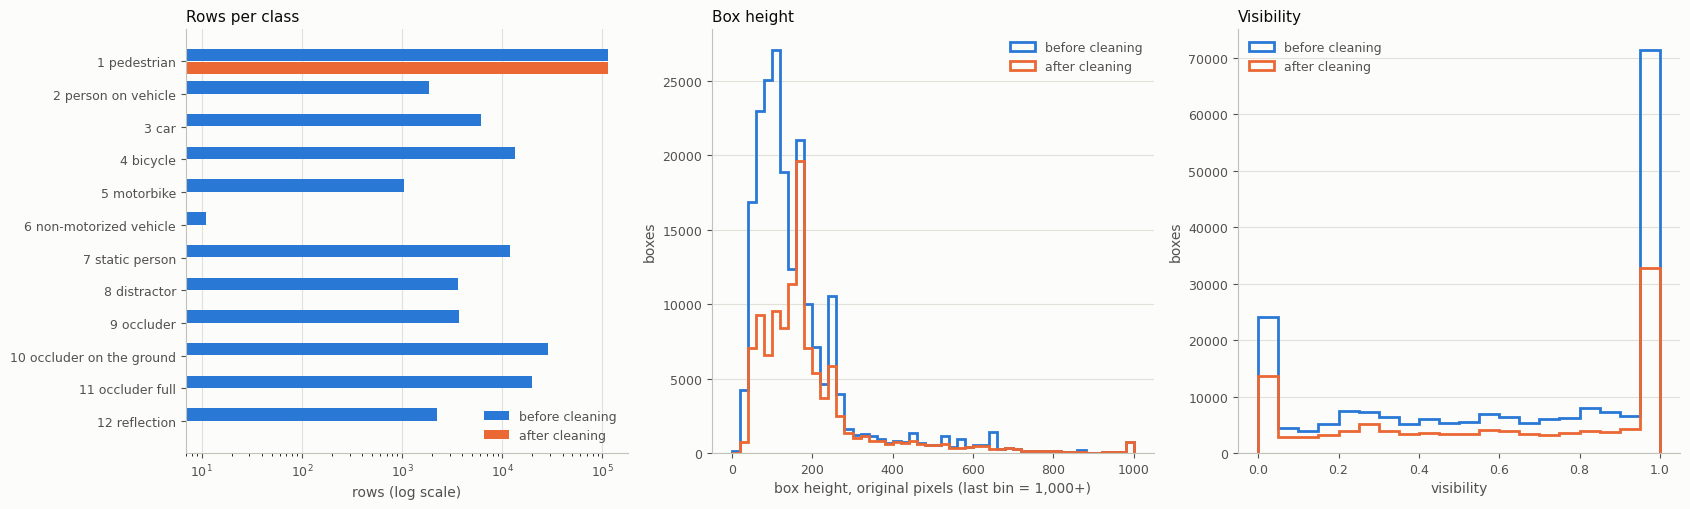

In [22]:
# Figure: what cleaning removes. Blue = before cleaning, orange = after cleaning (same colours in every panel).
BEFORE, AFTER = "#2a78d6", "#eb6834"
INK, INK_2, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), facecolor="#fcfcfb")
for ax in axes:
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="x" if ax is axes[0] else "y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=INK_2, labelsize=9)

# 1. Rows per class: cleaning keeps only class 1 (pedestrian) with use = 1.
counts = pd.DataFrame({"before": gt_before_cleaning["class"].value_counts(),
                       "after": ped["class"].value_counts()}).fillna(0).sort_index(ascending=False)
labels = [f"{c} {CLASS_NAMES.get(c, '?')}" for c in counts.index]
y = np.arange(len(counts))
axes[0].barh(y + 0.2, counts["before"], height=0.38, color=BEFORE, label="before cleaning")
axes[0].barh(y - 0.2, counts["after"], height=0.38, color=AFTER, label="after cleaning")
axes[0].set_yticks(y, labels)
axes[0].set_xscale("log")
axes[0].set_xlabel("rows (log scale)", color=INK_2)
axes[0].set_title("Rows per class", color=INK, loc="left", fontsize=11)

# 2. Box height (original pixels). Heights above 1,000 px are counted in the last bin.
bins = np.arange(0, 1020, 20)
for rows, colour, label in [(gt_before_cleaning, BEFORE, "before cleaning"), (ped, AFTER, "after cleaning")]:
    axes[1].hist(rows["height"].clip(upper=1000), bins=bins, histtype="step", linewidth=2, color=colour, label=label)
axes[1].set_xlabel("box height, original pixels (last bin = 1,000+)", color=INK_2)
axes[1].set_ylabel("boxes", color=INK_2)
axes[1].set_title("Box height", color=INK, loc="left", fontsize=11)

# 3. Visibility (0 = completely hidden, 1 = fully visible).
bins = np.linspace(0, 1, 21)
for rows, colour, label in [(gt_before_cleaning, BEFORE, "before cleaning"), (ped, AFTER, "after cleaning")]:
    axes[2].hist(rows["visibility"], bins=bins, histtype="step", linewidth=2, color=colour, label=label)
axes[2].set_xlabel("visibility", color=INK_2)
axes[2].set_ylabel("boxes", color=INK_2)
axes[2].set_title("Visibility", color=INK, loc="left", fontsize=11)

for ax in axes:
    ax.legend(frameon=False, fontsize=9, labelcolor=INK_2)
plt.tight_layout()
plt.savefig(OUTPUT_FIGURES / "before_after_cleaning.png", dpi=120, facecolor=fig.get_facecolor())
plt.show()

report["1.8 Statistics before and after cleaning"] = "\n\n".join([
    "Before = every readable gt.txt row (all classes, scored or not); after = the kept pedestrian boxes (boxes.csv). "
    "Sizes are in original pixels; standard deviations are sample standard deviations (ddof=1). "
    "Full per-video table: stats_before_after.csv. Figure: outputs/figures/before_after_cleaning.png.",
    md_table(before_after[["group", "stage", "frames", "boxes", "object_ids", "classes", "boxes_per_frame", "scored_pct"]]),
    md_table(before_after[["group", "stage", "height_mean", "height_std", "width_mean", "width_std", "area_mean",
                           "area_std", "visibility_mean", "visibility_0_pct", "past_edge_pct"]], decimals=2),
])

## 1.9 Outputs
Writes `frames.csv`, `boxes.csv`, `stats.csv`, `problems.csv` and `data_report.md` to `outputs/data/` (`pixel_stats.json` was saved in 1.6, `split_mix.csv` in 1.7).
Also writes the ready-made splits to `outputs/data/splits/`: `train_frames.csv`, `train_boxes.csv`, `val_frames.csv`, `val_boxes.csv`, `test_frames.csv`, `test_boxes.csv`.

For the other notebooks it also writes `videos.csv` (length, frame size and split of each video), `detections.csv` (MOT17's supplied Faster R-CNN detections, the input DeepSORT tracks from, values unchanged), and last `manifest.json` (MD5 of every prepared file).

In [23]:
# frames.csv: one row per kept frame of the 7 training videos (image paths are relative to DATA_ROOT).
frames_csv = frames_used[["split", "video", "frame", "image_path", "image_width", "image_height"]]
frames_csv = frames_csv.sort_values(["video", "frame"])
frames_csv.to_csv(OUTPUT_DATA / "frames.csv", index=False)

# boxes.csv: one row per kept box, as 0-1 fractions of the original frame.
boxes_csv = ped[["split", "video", "frame", "id", "cx", "cy", "w", "h", "visibility"]]
boxes_csv = boxes_csv.sort_values(["video", "frame", "id"])
boxes_csv.to_csv(OUTPUT_DATA / "boxes.csv", index=False)

# stats.csv: the statistics from 1.8.
stats.to_csv(OUTPUT_DATA / "stats.csv", index=False)

# problems.csv: every problem found (only the header if there were none).
problems_table = pd.DataFrame(problems, columns=["problem", "video", "frame", "id", "detail"])
problems_table.to_csv(OUTPUT_DATA / "problems.csv", index=False)


def write_report():
    """Write data_report.md from everything collected in `report` so far."""
    text = "# MOT17 data report (Phase 1)\n\n"
    text += f"Generated by `Exploratory data analysis.ipynb`. Problems recorded: {len(problems)} (see problems.csv).\n\n"
    for heading, body in report.items():
        text += f"## {heading}\n\n{body}\n\n"
    (OUTPUT_DATA / "data_report.md").write_text(text, encoding="utf-8")


# Ready-made split files: outputs/data/splits/<split>_frames.csv and <split>_boxes.csv.
# They hold exactly the rows of frames.csv / boxes.csv whose split column is that split (same columns, same order).
OUTPUT_SPLITS = OUTPUT_DATA / "splits"
OUTPUT_SPLITS.mkdir(exist_ok=True)
for s in SPLITS:
    frames_csv[frames_csv["split"] == s].to_csv(OUTPUT_SPLITS / f"{s}_frames.csv", index=False)
    boxes_csv[boxes_csv["split"] == s].to_csv(OUTPUT_SPLITS / f"{s}_boxes.csv", index=False)

# videos.csv: one row per video used, so other notebooks never need to read seqinfo.ini themselves.
videos_csv = videos[videos["video"].isin(list(SPLIT_OF_VIDEO))].copy()
videos_csv["split"] = videos_csv["video"].map(SPLIT_OF_VIDEO)
videos_csv["folder"] = "train/" + videos_csv["video"] + f"-{DETECTOR_COPY}"     # relative to DATA_ROOT
videos_csv["frames_kept"] = videos_csv["video"].map(frames_csv.groupby("video").size())
videos_csv = videos_csv[["split", "video", "folder", "seq_length", "frames_kept", "im_width", "im_height", "frame_rate"]]
videos_csv = videos_csv.sort_values("video")
videos_csv.to_csv(OUTPUT_DATA / "videos.csv", index=False)
display(videos_csv)

,split,video,folder,seq_length,frames_kept,im_width,im_height,frame_rate
0,train,MOT17-02,train/MOT17-02-FRCNN,600,600,1920,1080,30
1,train,MOT17-04,train/MOT17-04-FRCNN,1050,1050,1920,1080,30
2,train,MOT17-05,train/MOT17-05-FRCNN,837,837,640,480,14
3,train,MOT17-09,train/MOT17-09-FRCNN,525,525,1920,1080,30
4,val,MOT17-10,train/MOT17-10-FRCNN,654,654,1920,1080,30
5,train,MOT17-11,train/MOT17-11-FRCNN,900,900,1920,1080,30
6,test,MOT17-13,train/MOT17-13-FRCNN,750,750,1920,1080,25


In [24]:
# detections.csv: MOT17's supplied Faster R-CNN detections (det/det.txt of the FRCNN copy) for every video used.
# These are the boxes a tracker such as DeepSORT receives. The values are copied unchanged (original pixels);
# only the split and video columns are added and the always -1 id column is left out. det.txt is not sorted
# by frame, so rows are sorted by frame with a STABLE sort, which keeps the file's order within each frame.
DET_COLUMNS = ["frame", "id", "left", "top", "width", "height", "conf"]
det_tables, det_check = [], []
for video in sorted(SPLIT_OF_VIDEO):
    det = pd.read_csv(DATA_ROOT / "train" / f"{video}-{DETECTOR_COPY}" / "det" / "det.txt", header=None, names=DET_COLUMNS)
    seq_length = int(videos.set_index("video").loc[video, "seq_length"])
    bad = det.isna().any(axis=1) | ~det["frame"].between(1, seq_length) | (det["width"] <= 0) | (det["height"] <= 0)
    for r in det[bad].itertuples():
        add_problem("invalid_det_row", video, r.frame, detail="missing value, frame out of range or width/height <= 0")
    on_kept_frame = pd.Series([(video, f) not in dropped_frames for f in det["frame"]], index=det.index)
    kept = det[~bad & on_kept_frame].sort_values("frame", kind="stable")
    kept.insert(0, "video", video)
    kept.insert(0, "split", SPLIT_OF_VIDEO[video])
    det_tables.append(kept.drop(columns="id"))
    det_check.append({"video": video, "det_rows": len(det), "invalid": int(bad.sum()),
                      "on_dropped_frames": int((~on_kept_frame).sum()), "kept": len(kept),
                      "ids_all_minus_1": bool((det["id"] == -1).all()),
                      "conf_min": det["conf"].min(), "conf_max": det["conf"].max()})
detections_csv = pd.concat(det_tables, ignore_index=True)
detections_csv.to_csv(OUTPUT_DATA / "detections.csv", index=False)
display(pd.DataFrame(det_check))

,video,det_rows,invalid,on_dropped_frames,kept,ids_all_minus_1,conf_min,conf_max
0,MOT17-02,8186,0,0,8186,True,0.05,1.0
1,MOT17-04,28406,0,0,28406,True,0.05,1.0
2,MOT17-05,3848,0,0,3848,True,0.05,1.0
3,MOT17-09,3049,0,0,3049,True,0.05,1.0
4,MOT17-10,9701,0,0,9701,True,0.05,1.0
5,MOT17-11,6007,0,0,6007,True,0.05,1.0
6,MOT17-13,8442,0,0,8442,True,0.05,1.0


In [25]:
# manifest.json: an MD5 fingerprint of every prepared file other notebooks read, plus a short version ID.
# mot17_data.data_version() re-checks these hashes, so a notebook can't silently run on missing or changed data.
PREPARED = ["frames.csv", "boxes.csv", "videos.csv", "detections.csv", "pixel_stats.json"] \
           + [f"splits/{s}_{kind}.csv" for s in SPLITS for kind in ["frames", "boxes"]]
manifest_files = {name: mot17_data.file_md5(OUTPUT_DATA / name) for name in PREPARED}
code_md5 = mot17_data.file_md5(mot17_data.__file__)      # the shared loading code is part of the version too
manifest = {
    "version": hashlib.md5(json.dumps([manifest_files, code_md5], sort_keys=True).encode()).hexdigest()[:10],
    "written_by": "Exploratory data analysis.ipynb",
    "split_of_video": SPLIT_OF_VIDEO,
    "code_md5": code_md5,
    "files": manifest_files,
}
(OUTPUT_DATA / "manifest.json").write_text(json.dumps(manifest, indent=2))
print("Data version:", mot17_data.data_version(), "(checked by reading every prepared file back)")

write_report()
for name in PREPARED + ["manifest.json", "stats.csv", "stats_before_after.csv", "split_mix.csv", "problems.csv", "data_report.md"]:
    path = OUTPUT_DATA / name
    print(f"{name:24s} {path.stat().st_size / 1e6:7.2f} MB")
print(f"frames.csv rows: {len(frames_csv):,} | boxes.csv rows: {len(boxes_csv):,} | problems: {len(problems_table)}")
if len(problems_table):
    display(problems_table.groupby("problem").size())

Data version: 1cc27f8c06 (checked by reading every prepared file back)
frames.csv                  0.35 MB
boxes.csv                  11.13 MB
videos.csv                  0.00 MB
detections.csv              3.19 MB
pixel_stats.json            0.00 MB
splits/train_frames.csv     0.26 MB
splits/train_boxes.csv      8.71 MB
splits/val_frames.csv       0.04 MB
splits/val_boxes.csv        1.26 MB
splits/test_frames.csv      0.05 MB
splits/test_boxes.csv       1.16 MB
manifest.json               0.00 MB
stats.csv                   0.00 MB
stats_before_after.csv      0.01 MB
split_mix.csv               0.00 MB
problems.csv                0.00 MB
data_report.md              0.02 MB
frames.csv rows: 5,316 | boxes.csv rows: 112,297 | problems: 0


## 1.10 PyTorch datasets
`MOT17Frames` gives one frame at a time and `MOT17FramePairs` gives pairs of consecutive frames. Both live in `mot17_data.py` (section 0), read only the prepared files in `outputs/data/` (never the raw annotation files), check the data version first, and do no data augmentation.

In [26]:
# The dataset classes are defined once, in mot17_data.py (section 0), so the model notebook uses exactly these.
from mot17_data import MOT17Frames, MOT17FramePairs, collate_frames, collate_pairs, make_loader, batch_to_device

datasets = {s: (MOT17Frames(s), MOT17FramePairs(s)) for s in SPLITS}
for s, (frames_ds, pairs_ds) in datasets.items():
    print(f"{s:5s}: {len(frames_ds):5,} frames, {len(pairs_ds):5,} consecutive pairs")

# The ready-to-use splits, by name (one item per frame; use datasets[s][1] for consecutive-frame pairs).
train_set, val_set, test_set = (datasets[s][0] for s in SPLITS)
train_loader = make_loader(train_set, "train")    # shuffled
val_loader = make_loader(val_set, "val")          # not shuffled
test_loader = make_loader(test_set, "test")       # not shuffled; only for the final comparison with DeepSORT
print("train_set / val_set / test_set videos:",
      {s: sorted(d.frames["video"].unique()) for s, d in zip(SPLITS, [train_set, val_set, test_set])})

train: 3,912 frames, 3,907 consecutive pairs
val  :   654 frames,   653 consecutive pairs
test :   750 frames,   749 consecutive pairs
train_set / val_set / test_set videos: {'train': ['MOT17-02', 'MOT17-04', 'MOT17-05', 'MOT17-09', 'MOT17-11'], 'val': ['MOT17-10'], 'test': ['MOT17-13']}


In [27]:
# Load one batch from each dataset class (training split) and print the shapes.
# Batch size starts at 2 because each frame is large (about 2.1 million pixels).
batch = next(iter(make_loader(datasets["train"][0], "train")))     # pin_memory is on when CUDA is available
print("MOT17Frames batch:")
print("  images    ", tuple(batch["images"].shape), batch["images"].dtype)
print("  orig_sizes", batch["orig_sizes"].tolist())
print("  boxes     ", [tuple(b.shape) for b in batch["boxes"]])
print("  ids       ", [tuple(i.shape) for i in batch["ids"]])
print("  frames    ", list(zip(batch["videos"], batch["frames"])))
if DEVICE.type == "cuda":
    batch_on_gpu = batch_to_device(batch, DEVICE)     # how model code moves every batch: images, boxes and IDs
    print(f"  moved to {DEVICE}: images on {batch_on_gpu['images'].device}, boxes on {batch_on_gpu['boxes'][0].device}; "
          f"GPU memory in use: {torch.cuda.memory_allocated() / 1e6:.0f} MB")
    del batch_on_gpu
else:
    print(f"  CUDA not available (CPU build of PyTorch). Batch of images uses "
          f"{batch['images'].element_size() * batch['images'].nelement() / 1e6:.0f} MB of memory.")

previous, current = next(iter(make_loader(datasets["train"][1], "train")))
print("MOT17FramePairs batch:")
print("  t-1 images", tuple(previous["images"].shape), "frames", list(zip(previous["videos"], previous["frames"])))
print("  t   images", tuple(current["images"].shape), "frames", list(zip(current["videos"], current["frames"])))
print("  boxes t-1 ", [tuple(b.shape) for b in previous["boxes"]], "| boxes t", [tuple(b.shape) for b in current["boxes"]])

MOT17Frames batch:
  images     (2, 3, 1088, 1920) torch.float32
  orig_sizes [[1920, 1080], [1920, 1080]]
  boxes      [(26, 4), (11, 4)]
  ids        [(26,), (11,)]
  frames     [('MOT17-02', 91), ('MOT17-09', 451)]
  moved to cuda: images on cuda:0, boxes on cuda:0; GPU memory in use: 50 MB


MOT17FramePairs batch:
  t-1 images (2, 3, 1088, 1920) frames [('MOT17-05', 317), ('MOT17-05', 400)]
  t   images (2, 3, 1088, 1920) frames [('MOT17-05', 318), ('MOT17-05', 401)]
  boxes t-1  [(10, 4), (7, 4)] | boxes t [(10, 4), (7, 4)]


## 1.11 A sample, exactly as a model receives it
One training frame through `MOT17Frames`, the same path any model takes: the **input** (a normalized image tensor) and its **ground truth** (boxes and IDs). Each box is converted back to pixels and compared with the `gt.txt` row it came from. Saved to `outputs/data/sample/`.

Getting the same sample in another notebook:
```python
import mot17_data
train_set = mot17_data.MOT17Frames("train")
item = train_set[i]       # item["image"], item["boxes"], item["ids"], item["orig_size"], item["video"], item["frame"]
```

In [28]:
# A training frame with clearly visible people (MOT17-09, frame 300: 12 pedestrian boxes).
SAMPLE_VIDEO, SAMPLE_FRAME = "MOT17-09", 300
is_sample = (train_set.frames["video"] == SAMPLE_VIDEO) & (train_set.frames["frame"] == SAMPLE_FRAME)
sample_index = int(train_set.frames.index[is_sample][0])
item = train_set[sample_index]
image = item["image"]

print("MODEL INPUT")
print(f"  image      tensor {tuple(image.shape)} = (colour channels, height, width), {image.dtype}")
print(f"             normalized: per-channel mean {[round(x, 3) for x in image.mean(dim=(1, 2)).tolist()]}, "
      f"std {[round(x, 3) for x in image.std(dim=(1, 2)).tolist()]}, min {image.min():.3f}, max {image.max():.3f}")
print(f"  orig_size  {item['orig_size'].tolist()} = original (width, height), to turn predictions back into pixels")
print("  top-left 3 x 3 pixels of the red channel:")
print(image[0, :3, :3])
print()
print("GROUND TRUTH")
print(f"  boxes      tensor {tuple(item['boxes'].shape)} = one row per person: (cx, cy, w, h) as fractions of the original frame")
print(f"  ids        tensor {tuple(item['ids'].shape)} = person IDs {item['ids'].tolist()}")
print(f"  video, frame = {item['video']}, {item['frame']}")

MODEL INPUT
  image      tensor (3, 1088, 1920) = (colour channels, height, width), torch.float32
             normalized: per-channel mean [0.136, -0.028, -0.175], std [1.029, 1.104, 1.159], min -2.073, max 2.398
  orig_size  [1920, 1080] = original (width, height), to turn predictions back into pixels
  top-left 3 x 3 pixels of the red channel:
tensor([[-0.1443, -0.1443, -0.1443],
        [-0.1443, -0.1443, -0.1443],
        [-0.1443, -0.1443, -0.1443]])

GROUND TRUTH
  boxes      tensor (12, 4) = one row per person: (cx, cy, w, h) as fractions of the original frame
  ids        tensor (12,) = person IDs [1, 2, 7, 8, 10, 11, 12, 13, 18, 21, 22, 29]
  video, frame = MOT17-09, 300


In [29]:
# The ground truth as a table: each box from the dataset, the same box in original pixels, and the gt.txt row it came from.
truth = pd.DataFrame(item["boxes"].numpy(), columns=["cx", "cy", "w", "h"])
truth.insert(0, "id", item["ids"].numpy())
orig_width, orig_height = item["orig_size"].tolist()
truth = truth.join(boxes_to_pixels(truth, orig_width, orig_height).round(2))

raw = pd.read_csv(DATA_ROOT / "train" / f"{SAMPLE_VIDEO}-{DETECTOR_COPY}" / "gt" / "gt.txt", header=None, names=GT_COLUMNS)
raw = raw[raw["frame"] == SAMPLE_FRAME]
raw_kept = raw.set_index("id")[["left", "top", "width", "height", "visibility", "use", "class"]].add_prefix("gt.txt ")
truth = truth.join(raw_kept, on="id")
largest = max((truth[c] - truth[f"gt.txt {c}"]).abs().max() for c in ["left", "top", "width", "height"])
display(truth.round(4))
print(f"{len(truth)} boxes in the sample; gt.txt has {len(raw)} rows for this frame "
      f"({len(raw) - len(truth)} not pedestrians with use = 1, so not in the ground truth the model learns from).")
print(f"Largest difference between a converted box and its gt.txt row: {largest:.4f} px (boxes are stored as float32)")

,id,cx,cy,w,h,left,top,width,height,gt.txt left,gt.txt top,gt.txt width,gt.txt height,gt.txt visibility,gt.txt use,gt.txt class
0,1,0.7021,0.5028,0.0615,0.3000,1289.0,381.0,118.0,324.0,1289,381,118,324,0.0000,1,1
1,2,0.6547,0.5185,0.0656,0.2815,1194.0,408.0,126.0,304.0,1194,408,126,304,0.0000,1,1
2,7,0.7401,0.5144,0.0656,0.2843,1358.0,402.0,126.0,307.0,1358,402,126,307,0.0000,1,1
3,8,0.8479,0.4981,0.0646,0.2741,1566.0,390.0,124.0,296.0,1566,390,124,296,0.5117,1,1
4,10,0.7924,0.5181,0.0495,0.2287,1474.0,436.0,95.0,247.0,1474,436,95,247,0.3021,1,1
5,11,0.6841,0.5074,0.0714,0.3648,1245.0,351.0,137.0,394.0,1245,351,137,394,0.6545,1,1
6,12,0.7510,0.5315,0.0917,0.4000,1354.0,358.0,176.0,432.0,1354,358,176,432,1.0000,1,1
7,13,0.6227,0.5273,0.0714,0.3750,1127.0,367.0,137.0,405.0,1127,367,137,405,1.0000,1,1
8,18,0.9951,0.4852,0.0318,0.1833,1880.0,425.0,61.0,198.0,1880,425,61,198,0.6613,1,1
9,21,0.9104,0.5810,0.0531,0.1917,1697.0,524.0,102.0,207.0,1697,524,102,207,1.0000,1,1


12 boxes in the sample; gt.txt has 24 rows for this frame (12 not pedestrians with use = 1, so not in the ground truth the model learns from).
Largest difference between a converted box and its gt.txt row: 0.0000 px (boxes are stored as float32)


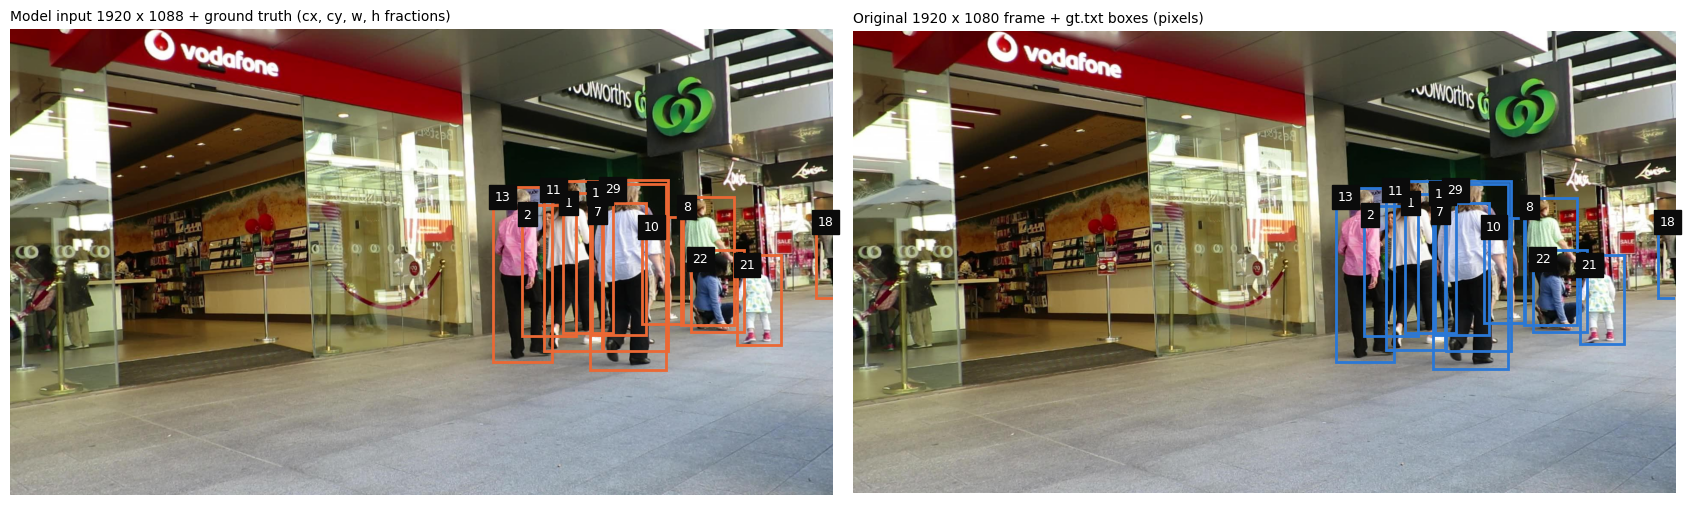

In [30]:
# Picture of the sample. Left: the model's input (resized to 1920 x 1088, normalization undone only so it can be
# shown) with the ground-truth fractions drawn at 1920 x 1088. Right: the original frame with the gt.txt pixel boxes.
# The boxes land on the same people in both, so the fractions are correct for the resized input too.
mean = torch.tensor(train_set.mean).view(3, 1, 1)
std = torch.tensor(train_set.std).view(3, 1, 1)
shown = (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()      # back to 0-1 RGB, height x width x 3

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
axes[0].imshow(shown)
for b in truth.itertuples():
    left, top = (b.cx - b.w / 2) * TARGET_WIDTH, (b.cy - b.h / 2) * TARGET_HEIGHT
    axes[0].add_patch(plt.Rectangle((left, top), b.w * TARGET_WIDTH, b.h * TARGET_HEIGHT, fill=False, edgecolor="#eb6834", linewidth=2))
    axes[0].text(left + 4, top + 30, str(b.id), color="white", fontsize=9, backgroundcolor="#0b0b0b")
axes[0].set_title(f"Model input {TARGET_WIDTH} x {TARGET_HEIGHT} + ground truth (cx, cy, w, h fractions)", fontsize=10, loc="left")

axes[1].imshow(open_original(f"train/{SAMPLE_VIDEO}-{DETECTOR_COPY}/img1/{SAMPLE_FRAME:06d}.jpg"))
for _, b in truth.iterrows():                    # the gt.txt pixel values, straight from the raw file
    axes[1].add_patch(plt.Rectangle((b["gt.txt left"], b["gt.txt top"]), b["gt.txt width"], b["gt.txt height"],
                                    fill=False, edgecolor="#2a78d6", linewidth=2))
    axes[1].text(b["gt.txt left"] + 4, b["gt.txt top"] + 30, str(int(b["id"])), color="white", fontsize=9, backgroundcolor="#0b0b0b")
axes[1].set_title(f"Original {orig_width} x {orig_height} frame + gt.txt boxes (pixels)", fontsize=10, loc="left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_FIGURES / "sample_model_input.png", dpi=110)
plt.show()

In [31]:
# The same frame as the second half of a consecutive-frame pair (what the transformer learns from):
# for each person in frame t, which box in frame t-1 is the same person (-1 = not in frame t-1).
pairs_train = datasets["train"][1]
pair_index = next(i for i, (_, current_index) in enumerate(pairs_train.pairs) if current_index == sample_index)
previous, current = pairs_train[pair_index]
previous_ids = previous["ids"].tolist()
match = [previous_ids.index(i) if i in previous_ids else -1 for i in current["ids"].tolist()]
pair_table = pd.DataFrame({"box in frame t": range(len(match)), "id": current["ids"].tolist(),
                           "same person's box in frame t-1": match})
print(f"PAIR: {current['video']} frames {previous['frame']} (t-1) and {current['frame']} (t): "
      f"{len(previous_ids)} and {len(match)} boxes; {sum(m >= 0 for m in match)} people in both, "
      f"{sum(m < 0 for m in match)} new in frame t")
display(pair_table)

# Save the sample: the exact item a model receives (torch.load it), and its ground truth as a table.
SAMPLE_DIR = OUTPUT_DATA / "sample"
SAMPLE_DIR.mkdir(exist_ok=True)
torch.save(item, SAMPLE_DIR / "sample_item.pt")
truth.to_csv(SAMPLE_DIR / "sample_ground_truth.csv", index=False)
reloaded = torch.load(SAMPLE_DIR / "sample_item.pt")
print("Saved", SAMPLE_DIR / "sample_item.pt", f"({(SAMPLE_DIR / 'sample_item.pt').stat().st_size / 1e6:.0f} MB) and sample_ground_truth.csv;",
      "reloads identical:", torch.equal(reloaded["image"], image) and torch.equal(reloaded["boxes"], item["boxes"]))

report["1.11 A sample, exactly as a model receives it"] = "\n\n".join([
    f"{SAMPLE_VIDEO} frame {SAMPLE_FRAME} through MOT17Frames('train'): image tensor {tuple(image.shape)} {image.dtype} "
    f"(resized, scaled to 0-1, normalized), boxes tensor {tuple(item['boxes'].shape)} (cx, cy, w, h fractions), "
    f"ids tensor {tuple(item['ids'].shape)}. Largest difference between a converted box and its gt.txt row: {largest:.4f} px. "
    "Saved as outputs/data/sample/sample_item.pt and sample_ground_truth.csv; figure: outputs/figures/sample_model_input.png.",
    md_table(truth, decimals=4),
])

PAIR: MOT17-09 frames 299 (t-1) and 300 (t): 12 and 12 boxes; 12 people in both, 0 new in frame t


,box in frame t,id,same person's box in frame t-1
0,0,1,0
1,1,2,1
2,2,7,2
3,3,8,3
4,4,10,4
5,5,11,5
6,6,12,6
7,7,13,7
8,8,18,8
9,9,21,9


Saved C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\data\sample\sample_item.pt (25 MB) and sample_ground_truth.csv; reloads identical: True


## 1.12 Checks
Each check prints PASS or FAIL with the numbers it compared. All checks are collected and summarised in the last cell.

In [32]:
check_results = []

def check(name, passed, detail):
    """Print and record the result of one check."""
    check_results.append({"check": name, "passed": bool(passed), "detail": detail})
    print(f"[{'PASS' if passed else 'FAIL'}] {name}: {detail}")


# Read the outputs back from disk, so the checks test the files rather than the notebook's variables.
frames_out = pd.read_csv(OUTPUT_DATA / "frames.csv")
boxes_out = pd.read_csv(OUTPUT_DATA / "boxes.csv")
stats_out = pd.read_csv(OUTPUT_DATA / "stats.csv").set_index("group")
pixel_stats_out = json.loads((OUTPUT_DATA / "pixel_stats.json").read_text())

# The statistics use cleaned boxes only.
overall_boxes = int(stats_out.loc["overall", "boxes_kept"])
check("statistics use cleaned boxes only", overall_boxes == len(boxes_out),
      f"overall boxes in stats.csv = {overall_boxes:,}, rows in boxes.csv = {len(boxes_out):,}")

# The groups add up: each split = sum of its videos; overall = sum of the splits.
for s in SPLITS:
    members = [v for v, sp in SPLIT_OF_VIDEO.items() if sp == s]
    for column in ["frames_kept", "boxes_kept"]:
        total = int(stats_out.loc[members, column].sum())
        check(f"{s} {column} adds up", total == stats_out.loc[s, column],
              f"sum of videos = {total:,}, split row = {int(stats_out.loc[s, column]):,}")
for column in ["frames_kept", "boxes_kept"]:
    total = int(stats_out.loc[SPLITS, column].sum())
    check(f"overall {column} adds up", total == stats_out.loc["overall", column],
          f"sum of splits = {total:,}, overall row = {int(stats_out.loc['overall', column]):,}")

# Spot-check one value by hand: MOT17-02's mean box width, recomputed straight from boxes.csv.
one = boxes_out[boxes_out["video"] == "MOT17-02"].merge(frames_out[["video", "frame", "image_width"]], on=["video", "frame"])
by_hand = (one["w"] * one["image_width"]).mean()
check("spot-check MOT17-02 mean width", abs(by_hand - stats_out.loc["MOT17-02", "width_mean"]) < 1e-6,
      f"from boxes.csv = {by_hand:.4f} px, stats.csv = {stats_out.loc['MOT17-02', 'width_mean']:.4f} px")

[PASS] statistics use cleaned boxes only: overall boxes in stats.csv = 112,297, rows in boxes.csv = 112,297
[PASS] train frames_kept adds up: sum of videos = 3,912, split row = 3,912
[PASS] train boxes_kept adds up: sum of videos = 87,816, split row = 87,816
[PASS] val frames_kept adds up: sum of videos = 654, split row = 654
[PASS] val boxes_kept adds up: sum of videos = 12,839, split row = 12,839
[PASS] test frames_kept adds up: sum of videos = 750, split row = 750
[PASS] test boxes_kept adds up: sum of videos = 11,642, split row = 11,642
[PASS] overall frames_kept adds up: sum of splits = 5,316, overall row = 5,316
[PASS] overall boxes_kept adds up: sum of splits = 112,297, overall row = 112,297
[PASS] spot-check MOT17-02 mean width: from boxes.csv = 54.6647 px, stats.csv = 54.6647 px


In [33]:
# Box values: widths and heights > 0; values outside 0-1 only on boxes that extend past the edge.
check("every box width and height > 0", ((boxes_out["w"] > 0) & (boxes_out["h"] > 0)).all(),
      f"smallest w = {boxes_out['w'].min():.5f}, smallest h = {boxes_out['h'].min():.5f}")

# The box's corners as fractions: outside 0-1 exactly when the box extends past the edge.
x1 = boxes_out["cx"] - boxes_out["w"] / 2
x2 = boxes_out["cx"] + boxes_out["w"] / 2
y1 = boxes_out["cy"] - boxes_out["h"] / 2
y2 = boxes_out["cy"] + boxes_out["h"] / 2
# Small tolerance, because converting to fractions and back can be off by about 1e-16.
eps = 1e-9
corner_outside = (x1 < -eps) | (y1 < -eps) | (x2 > 1 + eps) | (y2 > 1 + eps)
expected_edge = int(EXPECTED["extend_past_edge"].sum())
check("boxes with a corner outside 0-1 = boxes extending past the edge", int(corner_outside.sum()) == expected_edge,
      f"{int(corner_outside.sum()):,} found, {expected_edge:,} expected (table in 1.5)")

# The stored values themselves (cx, cy, w, h) outside 0-1. Two kinds of box have them:
#   - the centre is outside the frame (cx or cy not in [0, 1)): should match the "centre outside" column of 1.5;
#   - the box is wider or taller than the whole frame (w or h above 1), even with its centre inside.
# Every such box must also be one that extends past the edge.
centre_outside = (boxes_out["cx"] < 0) | (boxes_out["cy"] < 0) | (boxes_out["cx"] >= 1) | (boxes_out["cy"] >= 1)
larger_than_frame = (boxes_out["w"] > 1) | (boxes_out["h"] > 1)
value_outside = centre_outside | larger_than_frame
expected_centre = int(EXPECTED["centre_outside"].sum())
check("boxes with cx or cy outside 0-1 = centre-outside boxes", int(centre_outside.sum()) == expected_centre,
      f"{int(centre_outside.sum()):,} found, {expected_centre:,} expected (table in 1.5)")
check("values outside 0-1 appear only on boxes that extend past the edge", bool(corner_outside[value_outside].all()),
      f"{int(value_outside.sum()):,} boxes have a cx/cy/w/h value outside 0-1 = {int(centre_outside.sum()):,} centre outside "
      f"+ {int((larger_than_frame & ~centre_outside).sum()):,} larger than the frame with the centre inside; "
      f"all extend past the edge: {bool(corner_outside[value_outside].all())}")

# Pedestrian rows and IDs per video match the plan's table exactly.
per_video = boxes_out.groupby("video").agg(rows=("id", "size"), ids=("id", "nunique"))
mismatches = per_video[(per_video["rows"] != EXPECTED["ped_rows"]) | (per_video["ids"] != EXPECTED["ped_ids"])]
check("pedestrian rows and IDs per video match the plan", len(mismatches) == 0 and len(per_video) == 7,
      f"{7 - len(mismatches)} / 7 videos match; total rows {per_video['rows'].sum():,} (expected {EXPECTED['ped_rows'].sum():,}), "
      f"total IDs {per_video['ids'].sum()} (expected {EXPECTED['ped_ids'].sum()})")

[PASS] every box width and height > 0: smallest w = 0.00521, smallest h = 0.02222
[PASS] boxes with a corner outside 0-1 = boxes extending past the edge: 16,368 found, 16,368 expected (table in 1.5)
[PASS] boxes with cx or cy outside 0-1 = centre-outside boxes: 4,835 found, 4,835 expected (table in 1.5)
[PASS] values outside 0-1 appear only on boxes that extend past the edge: 6,189 boxes have a cx/cy/w/h value outside 0-1 = 4,835 centre outside + 1,354 larger than the frame with the centre inside; all extend past the edge: True
[PASS] pedestrian rows and IDs per video match the plan: 7 / 7 videos match; total rows 112,297 (expected 112,297), total IDs 546 (expected 546)


In [34]:
# Ground truth unchanged: for 100 random boxes, convert boxes.csv back to pixels and compare with gt.txt read fresh from disk.
sample = boxes_out.sample(100, random_state=SEED).merge(frames_out[["video", "frame", "image_width", "image_height"]],
                                                        on=["video", "frame"])
fresh_gt = {}
for v in sample["video"].unique():
    path = DATA_ROOT / "train" / f"{v}-{DETECTOR_COPY}" / "gt" / "gt.txt"
    fresh_gt[v] = pd.read_csv(path, header=None, names=GT_COLUMNS).set_index(["frame", "id"])

largest_error = 0.0
for r in sample.itertuples():
    width_px = r.w * r.image_width
    height_px = r.h * r.image_height
    left_px = r.cx * r.image_width - width_px / 2
    top_px = r.cy * r.image_height - height_px / 2
    original = fresh_gt[r.video].loc[(r.frame, r.id)]
    error = max(abs(left_px - original["left"]), abs(top_px - original["top"]),
                abs(width_px - original["width"]), abs(height_px - original["height"]))
    largest_error = max(largest_error, error)
check("100 random boxes convert back to their gt.txt pixels", largest_error < 1e-6,
      f"largest difference = {largest_error:.2e} px")

# No box belongs to a missing (dropped) frame: every box's frame is in frames.csv.
box_frames = set(zip(boxes_out["video"], boxes_out["frame"]))
kept_frame_set = set(zip(frames_out["video"], frames_out["frame"]))
orphans = len(box_frames - kept_frame_set)
check("no box belongs to a missing frame", orphans == 0 and not (box_frames & dropped_frames),
      f"{orphans} box frames not in frames.csv; {len(dropped_frames)} frames were dropped")

# No video appears in two splits.
splits_per_video = pd.concat([frames_out[["video", "split"]], boxes_out[["video", "split"]]]).drop_duplicates() \
                     .groupby("video")["split"].nunique()
check("no video appears in two splits", (splits_per_video == 1).all(),
      f"splits per video: {splits_per_video.to_dict()}")

# The split files in outputs/data/splits/ hold exactly the rows of frames.csv / boxes.csv for that split,
# and together they cover every row once.
split_files_ok = True
for kind, whole in [("frames", frames_out), ("boxes", boxes_out)]:
    parts = [pd.read_csv(OUTPUT_DATA / "splits" / f"{s}_{kind}.csv") for s in SPLITS]
    for s, part in zip(SPLITS, parts):
        expected = whole[whole["split"] == s].reset_index(drop=True)
        split_files_ok &= part.equals(expected)
    split_files_ok &= sum(len(p) for p in parts) == len(whole)
check("split files match frames.csv / boxes.csv", split_files_ok,
      "train/val/test _frames.csv and _boxes.csv: " +
      ", ".join(f"{s} {len(frames_out[frames_out['split'] == s]):,} frames / {len(boxes_out[boxes_out['split'] == s]):,} boxes"
                for s in SPLITS))

[PASS] 100 random boxes convert back to their gt.txt pixels: largest difference = 2.27e-13 px
[PASS] no box belongs to a missing frame: 0 box frames not in frames.csv; 0 frames were dropped


[PASS] no video appears in two splits: splits per video: {'MOT17-02': 1, 'MOT17-04': 1, 'MOT17-05': 1, 'MOT17-09': 1, 'MOT17-10': 1, 'MOT17-11': 1, 'MOT17-13': 1}
[PASS] split files match frames.csv / boxes.csv: train/val/test _frames.csv and _boxes.csv: train 3,912 frames / 87,816 boxes, val 654 frames / 12,839 boxes, test 750 frames / 11,642 boxes


In [35]:
# The files other notebooks read: detections.csv, videos.csv, the manifest, and the before/after statistics.

# detections.csv holds every det.txt row unchanged: compare with det.txt read fresh from disk, video by video.
detections_out = pd.read_csv(OUTPUT_DATA / "detections.csv")
det_same = True
for video in sorted(SPLIT_OF_VIDEO):
    fresh = pd.read_csv(DATA_ROOT / "train" / f"{video}-{DETECTOR_COPY}" / "det" / "det.txt", header=None, names=DET_COLUMNS)
    fresh = fresh.sort_values("frame", kind="stable").drop(columns="id").reset_index(drop=True)
    ours = detections_out[detections_out["video"] == video].drop(columns=["split", "video"]).reset_index(drop=True)
    det_same &= ours.equals(fresh)
check("detections.csv = det.txt rows, values unchanged", det_same,
      f"{len(detections_out):,} rows over {detections_out['video'].nunique()} videos; "
      f"per video: {detections_out.groupby('video').size().to_dict()}")

# videos.csv matches seqinfo.ini and the split.
videos_out = pd.read_csv(OUTPUT_DATA / "videos.csv").set_index("video")
seqinfo = videos.set_index("video").loc[videos_out.index]
videos_ok = ((videos_out[["seq_length", "im_width", "im_height", "frame_rate"]] == seqinfo[["seq_length", "im_width", "im_height", "frame_rate"]]).all().all()
             and (videos_out["split"] == videos_out.index.map(SPLIT_OF_VIDEO)).all()
             and (videos_out["frames_kept"] == frames_out.groupby("video").size().loc[videos_out.index]).all())
check("videos.csv matches seqinfo.ini, the split and frames.csv", videos_ok, f"{len(videos_out)} videos")

# The manifest verifies: every prepared file has the MD5 recorded in manifest.json.
version = mot17_data.data_version()
manifest_out = json.loads((OUTPUT_DATA / "manifest.json").read_text())
check("manifest.json matches every prepared file", version == manifest_out["version"],
      f"data version {version}; {len(manifest_out['files'])} files checked by MD5")

# Before/after statistics: 'before' counts every gt.txt row, 'after' counts every box in boxes.csv.
ba = pd.read_csv(OUTPUT_DATA / "stats_before_after.csv").set_index(["group", "stage"])
before_rows, after_rows = int(ba.loc[("overall", "before cleaning"), "boxes"]), int(ba.loc[("overall", "after cleaning"), "boxes"])
check("before/after statistics count the right rows", before_rows == sum(gt_raw_counts.values()) and after_rows == len(boxes_out),
      f"before = {before_rows:,} (gt.txt rows {sum(gt_raw_counts.values()):,}), after = {after_rows:,} (boxes.csv rows {len(boxes_out):,})")

# The shared conversion boxes_to_pixels() gives back EXACTLY the gt.txt pixel values for every box in boxes.csv
# (this is what DeepSORT's ground-truth run receives).
with_size = boxes_out.merge(frames_out[["video", "frame", "image_width", "image_height"]], on=["video", "frame"])
converted = boxes_to_pixels(with_size, with_size["image_width"], with_size["image_height"])
exact = gt_before_cleaning.set_index(["video", "frame", "id"]).loc[
    list(zip(with_size["video"], with_size["frame"], with_size["id"])), ["left", "top", "width", "height"]].to_numpy()
exact_share = (converted.to_numpy() == exact).all(axis=1).mean()
check("boxes_to_pixels gives exactly the gt.txt values for every box", exact_share == 1,
      f"{100 * exact_share:.2f}% of {len(with_size):,} boxes exact (all four values)")

# The saved sample matches the dataset and gt.txt.
check("sample boxes convert back to their gt.txt pixels", largest < 0.01 and len(truth) > 0,
      f"{SAMPLE_VIDEO} frame {SAMPLE_FRAME}: {len(truth)} boxes, largest difference {largest:.4f} px")

[PASS] detections.csv = det.txt rows, values unchanged: 67,639 rows over 7 videos; per video: {'MOT17-02': 8186, 'MOT17-04': 28406, 'MOT17-05': 3848, 'MOT17-09': 3049, 'MOT17-10': 9701, 'MOT17-11': 6007, 'MOT17-13': 8442}
[PASS] videos.csv matches seqinfo.ini, the split and frames.csv: 7 videos
[PASS] manifest.json matches every prepared file: data version 1cc27f8c06; 11 files checked by MD5
[PASS] before/after statistics count the right rows: before = 204,701 (gt.txt rows 204,701), after = 112,297 (boxes.csv rows 112,297)


[PASS] boxes_to_pixels gives exactly the gt.txt values for every box: 100.00% of 112,297 boxes exact (all four values)
[PASS] sample boxes convert back to their gt.txt pixels: MOT17-09 frame 300: 12 boxes, largest difference 0.0000 px


In [36]:
# Normalization: pixel_stats.json has 3 means and 3 standard deviations computed from training frames only.
train_only = set(pixel_stats_out["videos"]) == {v for v, s in SPLIT_OF_VIDEO.items() if s == "train"}
check("pixel_stats.json: 3 means, 3 stds, training frames only",
      len(pixel_stats_out["mean"]) == 3 and len(pixel_stats_out["std"]) == 3 and train_only
      and pixel_stats_out["computed_on_split"] == "train",
      f"mean {np.round(pixel_stats_out['mean'], 4).tolist()}, std {np.round(pixel_stats_out['std'], 4).tolist()}, "
      f"videos {pixel_stats_out['videos']}")

# Normalized training frames should have per-channel mean close to 0 and std close to 1.
# 16 random training frames (8 shuffled batches of 2), so the sample covers several videos.
loader = make_loader(datasets["train"][0], "train")
images = torch.cat([b["images"] for b, _ in zip(loader, range(8))])
channel_mean = images.mean(dim=(0, 2, 3))
channel_std = images.std(dim=(0, 2, 3))
check("normalized training frames: mean close to 0, std close to 1",
      bool((channel_mean.abs() < 0.3).all() and ((channel_std - 1).abs() < 0.3).all()),
      f"{images.shape[0]} frames; mean {np.round(channel_mean.numpy(), 3).tolist()}, std {np.round(channel_std.numpy(), 3).tolist()} "
      f"(tolerance 0.3, because a small sample differs from the full-split average)")
del images

# The boxes returned for a frame are identical with and without normalization.
plain = MOT17Frames("train", normalize=False)
normalized = datasets["train"][0]
same = all(torch.equal(plain[i]["boxes"], normalized[i]["boxes"]) and torch.equal(plain[i]["ids"], normalized[i]["ids"])
           for i in [0, 500, 1500])
check("boxes identical with and without normalization", same, "compared frames 0, 500 and 1500 of the training split")

[PASS] pixel_stats.json: 3 means, 3 stds, training frames only: mean [0.4636, 0.4629, 0.442], std [0.2236, 0.234, 0.2351], videos ['MOT17-02', 'MOT17-04', 'MOT17-05', 'MOT17-09', 'MOT17-11']


[PASS] normalized training frames: mean close to 0, std close to 1: 16 frames; mean [-0.07500000298023224, -0.07800000160932541, -0.05700000002980232], std [1.0010000467300415, 0.9879999756813049, 0.9750000238418579] (tolerance 0.3, because a small sample differs from the full-split average)


[PASS] boxes identical with and without normalization: compared frames 0, 500 and 1500 of the training split


In [37]:
# Frame sizes: load one frame from every video (and its first frame) through the dataset class.
# Checks the tensor shape, that the returned original size matches seqinfo.ini, and that the returned
# boxes convert back to their gt.txt pixels (so resizing leaves the ground truth unchanged).
seqinfo_size = videos.set_index("video")[["im_width", "im_height"]]
shape_ok = size_ok = True
largest_error = 0.0
for s in SPLITS:
    ds = datasets[s][0]
    first_of_each_video = ds.frames.groupby("video").head(1).index
    for i in first_of_each_video:
        item = ds[i]
        shape_ok &= tuple(item["image"].shape) == (3, TARGET_HEIGHT, TARGET_WIDTH)
        expected_size = seqinfo_size.loc[item["video"]].tolist()
        size_ok &= item["orig_size"].tolist() == expected_size
        # Boxes back to original pixels using the ORIGINAL size, compared with gt.txt.
        width_px = item["boxes"][:, 2].double() * expected_size[0]
        height_px = item["boxes"][:, 3].double() * expected_size[1]
        left_px = item["boxes"][:, 0].double() * expected_size[0] - width_px / 2
        top_px = item["boxes"][:, 1].double() * expected_size[1] - height_px / 2
        gt = pd.read_csv(DATA_ROOT / "train" / f"{item['video']}-{DETECTOR_COPY}" / "gt" / "gt.txt", header=None, names=GT_COLUMNS)
        gt = gt[(gt["frame"] == item["frame"]) & (gt["use"] == 1) & (gt["class"] == 1)].set_index("id").loc[item["ids"].tolist()]
        for got, column in [(left_px, "left"), (top_px, "top"), (width_px, "width"), (height_px, "height")]:
            largest_error = max(largest_error, float((got - torch.tensor(gt[column].to_numpy(), dtype=torch.float64)).abs().max()))

check("image tensors are [3, 1088, 1920]", shape_ok, "first frame of each of the 7 videos, via MOT17Frames")
check("returned original size matches seqinfo.ini", size_ok, "first frame of each of the 7 videos")
with_seqinfo = frames_out.join(seqinfo_size, on="video")
frames_csv_sizes_ok = ((with_seqinfo["image_width"] == with_seqinfo["im_width"])
                       & (with_seqinfo["image_height"] == with_seqinfo["im_height"])).all()
check("frames.csv sizes match seqinfo.ini for every frame", frames_csv_sizes_ok, f"{len(frames_out):,} frames")
check("dataset boxes convert back to gt.txt pixels with the original size", largest_error < 0.01,
      f"largest difference = {largest_error:.2e} px (float32 boxes)")

[PASS] image tensors are [3, 1088, 1920]: first frame of each of the 7 videos, via MOT17Frames
[PASS] returned original size matches seqinfo.ini: first frame of each of the 7 videos
[PASS] frames.csv sizes match seqinfo.ini for every frame: 5,316 frames
[PASS] dataset boxes convert back to gt.txt pixels with the original size: largest difference = 5.44e-05 px (float32 boxes)


[PASS] sample figures saved: 9 images in C:\Users\nepul\Documents\APS360-2026-Multi-Object-Tracking-Project\outputs\figures


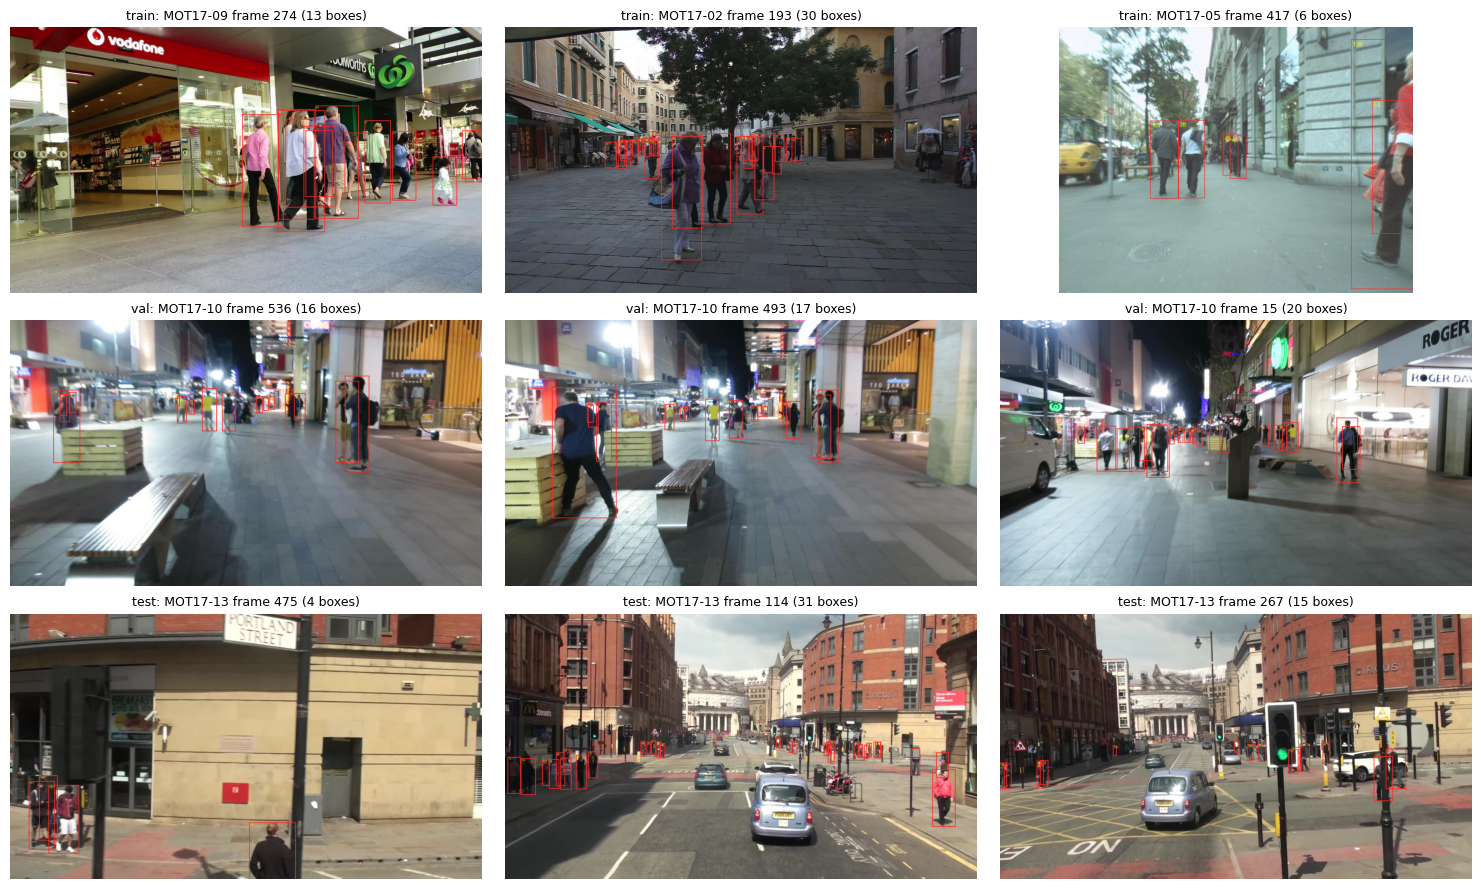

In [38]:
# Visual check: 3 frames per split with their boxes and IDs drawn on the ORIGINAL frame (not resized, not normalized).
# Boxes come from boxes.csv and are turned back into pixels with the frame's original size.
saved = []
for s in SPLITS:
    split_frames = frames_out[frames_out["split"] == s]
    for r in split_frames.sample(3, random_state=SEED).itertuples():
        image = Image.open(DATA_ROOT / r.image_path).convert("RGB")
        draw = ImageDraw.Draw(image)
        line = 3 if r.image_width > 1000 else 1
        boxes = boxes_out[(boxes_out["video"] == r.video) & (boxes_out["frame"] == r.frame)]
        for b in boxes.itertuples():
            left = (b.cx - b.w / 2) * r.image_width
            top = (b.cy - b.h / 2) * r.image_height
            right = left + b.w * r.image_width
            bottom = top + b.h * r.image_height
            draw.rectangle([left, top, right, bottom], outline=(255, 40, 40), width=line)
            draw.text((left + 3, top + 2), str(b.id), fill=(255, 255, 0))
        path = OUTPUT_FIGURES / f"{s}_{r.video}_{r.frame:06d}.jpg"
        image.save(path, quality=90)
        saved.append((s, r.video, r.frame, len(boxes), image))
check("sample figures saved", len(saved) == 9, f"{len(saved)} images in {OUTPUT_FIGURES}")

# Show small versions here; the full-size images are in outputs/figures/.
fig, axes = plt.subplots(3, 3, figsize=(15, 9))
for ax, (s, video, frame, n, image) in zip(axes.flat, saved):
    ax.imshow(image)
    ax.set_title(f"{s}: {video} frame {frame} ({n} boxes)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [39]:
# Loader check: one batch from each dataset class and each split, with tensor shapes.
for s in SPLITS:
    frames_ds, pairs_ds = datasets[s]
    batch = next(iter(make_loader(frames_ds, s)))
    previous, current = next(iter(make_loader(pairs_ds, s)))
    ok = (tuple(batch["images"].shape) == (2, 3, TARGET_HEIGHT, TARGET_WIDTH)
          and tuple(current["images"].shape) == (2, 3, TARGET_HEIGHT, TARGET_WIDTH)
          and all(b.shape[1] == 4 for b in batch["boxes"])
          and all(c - p == 1 and vc == vp for p, c, vp, vc in zip(previous["frames"], current["frames"],
                                                                   previous["videos"], current["videos"])))
    check(f"{s} loaders", ok,
          f"frames: images {tuple(batch['images'].shape)}, boxes {[tuple(b.shape) for b in batch['boxes']]}, "
          f"ids {[tuple(i.shape) for i in batch['ids']]} | pairs: images 2 x {tuple(current['images'].shape)}, "
          f"frames {list(zip(previous['frames'], current['frames']))}")

[PASS] train loaders: frames: images (2, 3, 1088, 1920), boxes [(40, 4), (6, 4)], ids [(40,), (6,)] | pairs: images 2 x (2, 3, 1088, 1920), frames [(41, 42), (525, 526)]
[PASS] val loaders: frames: images (2, 3, 1088, 1920), boxes [(19, 4), (19, 4)], ids [(19,), (19,)] | pairs: images 2 x (2, 3, 1088, 1920), frames [(1, 2), (2, 3)]


[PASS] test loaders: frames: images (2, 3, 1088, 1920), boxes [(22, 4), (22, 4)], ids [(22,), (22,)] | pairs: images 2 x (2, 3, 1088, 1920), frames [(1, 2), (2, 3)]


## Summary

In [40]:
# Short summary of Phase 1, and the checks added to data_report.md.
checks_table = pd.DataFrame(check_results)
overall = stats.set_index("group").loc["overall"]

print("=== Data left after cleaning (7 training videos) ===")
print(f"Frames: {int(overall['frames_kept']):,} of {int(overall['frames_expected']):,} kept ({overall['frames_kept_pct']:.1f}%)")
print(f"Boxes:  {int(overall['boxes_kept']):,} of {int(overall['rows_raw']):,} gt.txt rows kept ({overall['boxes_kept_pct']:.1f}%)")
print(f"People: {int(overall['ids_kept']):,} IDs | {overall['boxes_per_frame']:.1f} boxes per frame")
print(f"Split frames: " + ", ".join(f"{s} {int(stats.set_index('group').loc[s, 'frames_kept']):,}" for s in SPLITS))
print()
print("=== Box size, all cleaned boxes (original pixels, mean ± std) ===")
print(f"Length (height): {overall['length_mean']:.1f} ± {overall['length_std']:.1f} px")
print(f"Width:           {overall['width_mean']:.1f} ± {overall['width_std']:.1f} px")
print(f"Area:            {overall['area_mean']:,.1f} ± {overall['area_std']:,.1f} px²")
print()
print(f"Data version: {mot17_data.data_version()} (other notebooks print this too, to show they use the same data)")
print(f"Problems recorded: {len(problems)} | Checks passed: {checks_table['passed'].sum()} / {len(checks_table)}")
for r in checks_table[~checks_table["passed"]].itertuples():
    print("  FAILED:", r.check, "-", r.detail)

report["1.12 Checks"] = (f"{checks_table['passed'].sum()} of {len(checks_table)} checks passed.\n\n"
                         + md_table(checks_table[["check", "passed", "detail"]]))
write_report()
print("data_report.md updated with the checks.")

=== Data left after cleaning (7 training videos) ===
Frames: 5,316 of 5,316 kept (100.0%)
Boxes:  112,297 of 204,701 gt.txt rows kept (54.9%)
People: 546 IDs | 21.1 boxes per frame
Split frames: train 3,912, val 654, test 750

=== Box size, all cleaned boxes (original pixels, mean ± std) ===
Length (height): 196.4 ± 160.0 px
Width:           69.7 ± 62.4 px
Area:            23,343.5 ± 64,378.9 px²

Data version: 1cc27f8c06 (other notebooks print this too, to show they use the same data)
Problems recorded: 0 | Checks passed: 36 / 36
data_report.md updated with the checks.
